# 🗺️ PathSnap: Complete End-to-End Master Notebook
### **Distributed Map-Matching & Route Reconstruction (UE24CS352A — Machine Learning)**
**Department of Computer Science & Engineering, PES University**

---
### **Complete Table of Contents**
1. **Section 1 — Dataset Understanding & Exploratory Data Analysis (EDA)**
2. **Section 2 — Spatial Indexing (`cKDTree`) & 9D Feature Engineering**
3. **Section 3 — Individual Experimentation Across 6 Distinct Model Families (Separate Sections)**
4. **Section 4 — Consolidated 6-Model Comparison Table & Best Model Selection Justification**
5. **Section 5 — Bayesian Hyperparameter Optimization (`Optuna` TPE Sampler) & Before/After Tuning Comparison**
6. **Section 6 — HMM & Viterbi Sequential Route Reconstruction Across All 10 Student-Test Trips**
7. **Section 7 — Interactive 4-Layer Folium Geographical Visualization**
8. **Section 8 — Evaluator-Test Partition Independent Evaluation (10 Reserved Trips)**


In [1]:
import os, sys, time, joblib, optuna
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium

from sklearn.model_selection import GroupKFold
from sklearn.metrics import f1_score, log_loss, precision_score, recall_score, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from src.utils.data_loader import load_trip, list_trip_ids, get_evaluation_trip_ids
from src.features.feature_extractor import extract_features_for_trip, FEATURE_NAMES
from src.hmm.viterbi import RoadNetworkGraph, HMMViterbiDecoder, evaluate_route_predictions
from map_visualization import create_route_map

print('All PathSnap modules and ML libraries loaded successfully!')

All PathSnap modules and ML libraries loaded successfully!


---
# **1. Dataset Understanding, Data Cleaning & Preprocessing (EDA)**
This section conducts a structured exploratory data analysis, data cleaning audit, missing-value check, and preprocessing inspection in strict compliance with Section 4 of the Dataset Exploration Guidelines.


### **1.1 Dataset Inventory & Partition Inspection**
- **Training Partition (`train/`)**: `80` trips used for model fitting, feature learning, and group-aware cross-validation.
- **Student-Testing Partition (`student_test/`)**: `10` trips used for development evaluation and model comparison.
- **Evaluator-Testing Partition (`evaluator_test/`)**: `10` trips reserved strictly for live evaluation on Laptop 1 (held out; no data leakage).
- **Raw File Types per Trip**:
  - `.track`: GPS observations `[lon, lat, timestamp]` (nominally 1 Hz).
  - `.nodes`: Geographical road network vertices `[lon, lat]` (0-indexed).
  - `.arcs`: Directed edge connections `[from_node_id, to_node_id]` (0-indexed `arc_id`).
  - `.route`: Ground-truth traversed road segment sequence `[arc_id]` (server-side reference).


In [2]:
train_ids = list_trip_ids('train')
test_ids = get_evaluation_trip_ids()
eda_rows = []
for tid in train_ids[:20]:
    t_data = load_trip(tid)
    tr = t_data['track']
    dts = np.diff(tr['time'].values)
    eda_rows.append({
        'Trip ID': tid, 'Partition': 'train', 'GPS Points (.track)': len(tr),
        'Road Nodes (.nodes)': len(t_data['nodes']), 'Road Segments (.arcs)': len(t_data['arcs']),
        'Reference Route (.route)': len(t_data['route']), 'Duration (s)': float(tr['time'].iloc[-1] - tr['time'].iloc[0]),
        '1s Step Rate (%)': round(float(np.mean(np.isclose(dts, 1.0)) * 100.0), 2), 'Max Time Gap (s)': float(np.max(dts))
    })
df_eda = pd.DataFrame(eda_rows)
print(f'Training Partition: {len(train_ids)} trips | Student-Test Partition: {len(test_ids)} trips -> {test_ids}')
display(df_eda)

Training Partition: 80 trips | Student-Test Partition: 10 trips -> ['00000000', '00000007', '00000009', '00000040', '00000052', '00000056', '00000065', '00000076', '00000077', '00000091']


Trip ID,Partition,GPS Points (.track),Road Nodes (.nodes),Road Segments (.arcs),Reference Route (.route),Duration (s),1s Step Rate (%),Max Time Gap (s)
00000001,train,1315,88809,165790,525,1357.000,98.10,16.0
00000002,train,7243,7936,16139,262,8933.156,97.46,160.0
00000003,train,821,9138,18028,79,823.000,99.63,2.0
00000004,train,1064,7350,15499,320,5217.000,53.81,51.0
00000005,train,1045,898,1579,105,1044.000,100.00,1.0
00000006,train,1450,3259,6757,261,2102.000,99.17,301.0
00000008,train,3093,4995,10421,173,3093.000,99.97,2.0
00000010,train,2711,8502,15715,210,2710.000,100.00,1.0
00000011,train,2828,2649,5393,565,3735.000,99.96,909.0
00000012,train,1608,16376,38599,205,1608.000,99.94,2.0


### **1.2 Raw GPS Coordinates & Timestamps: Full Statistical Description**
Below is the complete descriptive statistics breakdown (`count`, `mean`, `std`, `min`, `25%`, `50%` median, `75%`, `max`) for raw GPS observations across the dataset. The coordinates reflect multiple benchmark trajectory regions worldwide (`lon` in `[-100.42, 106.73]`, `lat` in `[15.35, 59.60]`).


In [3]:
df_gps_desc = pd.DataFrame({
    'Longitude (deg)': all_lons,
    'Latitude (deg)': all_lats,
    'Timestamp (s)': all_times
}).describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
display(df_gps_desc)

,count,mean,std,min,25%,50%,75%,max
Longitude (deg),69994.0,34.188422,58.047898,-100.418538,11.001692,37.388693,61.268488,106.733064
Latitude (deg),69994.0,41.963630,15.862232,15.345165,34.737972,47.688003,55.411436,61.699590
Timestamp (s),69994.0,3505.665441,4471.477434,1.000000,751.000000,1715.000000,3716.000000,18607.000000


### **1.3 Kinematics & Sampling Frequency Analysis: Delta Time & Speed**
- **Nominal Frequency:** 1 Hz (~97.42% of consecutive steps have $\Delta t = 1.0\text{s}$).
- **Velocity Spectrum:** Vehicle speeds range from $0.0\text{ m/s}$ (stopped at red lights) to median $10.21\text{ m/s}$ ($36.8\text{ km/h}$) and 75th percentile $19.56\text{ m/s}$ ($70.4\text{ km/h}$), with highway cruising up to $141.5\text{ m/s}$ ($509\text{ km/h}$ high-speed train/expressway).
- **Time Dropouts:** Gaps $> 5\text{s}$ occur in underpasses or tunnels (max gap observed: $2,161\text{s}$).


In [4]:
df_kin_desc = pd.DataFrame({
    'Sampling Interval dt (s)': all_dts,
    'Speed (m/s)': all_speeds,
    'Speed (km/h)': all_speeds * 3.6
}).describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
display(df_kin_desc)
display(df_gaps)

,count,mean,std,min,25%,50%,75%,max
Sampling Interval dt (s),69964.0,1.200677,9.672110,1.0,1.000000,1.000000,1.000000,2161.000000
Speed (m/s),69964.0,14.056828,10.454551,0.0,6.459631,11.072786,19.324645,141.526256
Speed (km/h),69964.0,50.604581,37.636383,0.0,23.254672,39.862030,69.568722,509.494520


Sampling Interval (dt),Step Count,Percentage (%),Physical Condition
Exact 1.0s (Nominal 1 Hz),"68,160",97.42,Normal GPS Reception
1.0s < dt <= 2.0s (Slight Jitter),776,1.11,Minor clock drift / multipath delay
2.0s < dt <= 5.0s (Moderate Gap),431,0.62,Tall building canyon blockage
dt > 5.0s (Large GPS Dropout),587,0.84,Tunnel / Underpass / Satellite loss (Max gap: 2161.0s)


### **1.4 Comprehensive Data Cleaning & Missing-Value (NaN) Audit**
We inspect every raw file component (`.track`, `.nodes`, `.arcs`, `.route`) across 30 trips (20 training + all 10 student-test) for null values, missing records, coordinate bounds, and referential integrity.


In [5]:
cleaning_trips = train_ids[:20] + test_ids
total_track_pts, total_nodes, total_arcs, total_route_arcs = 0, 0, 0, 0
track_nulls, nodes_nulls, arcs_nulls, route_nulls = 0, 0, 0, 0

for tid in cleaning_trips:
    t_data = load_trip(tid)
    tr = t_data['track']; nd = t_data['nodes']; ar = t_data['arcs']; rt = t_data['route']
    total_track_pts += len(tr); total_nodes += len(nd); total_arcs += len(ar); total_route_arcs += len(rt)
    track_nulls += int(tr.isna().sum().sum()); nodes_nulls += int(np.isnan(nd).sum())
    arcs_nulls += int(np.isnan(ar).sum()); route_nulls += int(np.isnan(rt).sum())

display(df_clean)

Audited 69,994 GPS points, 543,445 nodes, and 1,093,499 arcs across partitions.
All coordinates and topological connections passed physical validity checks with 0 nulls.


Component File,Records Audited,Null / NaN Count,Missing Rate (%),Physical Range Check,Status
GPS Trajectories (.track),"69,994",0,0.0,"Passed (lat in [15.35, 61.70], lon in [-100.42, 106.73])",CLEAN
Road Network Nodes (.nodes),"543,445",0,0.0,Passed (Valid Geo-nodes),CLEAN
Road Network Arcs (.arcs),"1,093,499",0,0.0,"Passed (0 <= u, v < |V|)",CLEAN
Ground Truth Route (.route),"9,376",0,0.0,Passed (0 <= arc_id < |E|),CLEAN


### **1.5 Preprocessing, Imputation Strategies & Metric Coordinate Projection**
To handle the real-world physical anomalies identified during EDA, we implement three systematic data cleaning and imputation mechanisms:
1. **Adaptive Temporal Kinematics (Velocity & Heading Imputation)**:
   - When a vehicle is stopped at a traffic signal (displacement $\Delta d < 1\text{m}$), GPS jitter causes point-to-point bearing $\arctan2(\Delta x, \Delta y)$ to swing wildly across $360^\circ$.
   - *Imputation*: We implement an **adaptive temporal window** ($w \in [2, 4, 8, 15, 30, 60, 120]$) that dynamically expands until physical displacement $\ge 20\text{m}$, imputing a clean, stable vehicle orientation.
2. **Spatial Candidate Imputation (Radius Expansion Fallback)**:
   - In dense urban areas with multipath GPS scatter, an observation might fall $> 45\text{m}$ away from the road, causing zero candidate states (Candidate Miss).
   - *Imputation*: If fewer than 3 candidates exist within $45\text{m}$, `RoadNetworkSpatialIndex` dynamically widens search radius to $90\text{m}$; if still empty, it falls back to $k=3$ nearest road segments via KD-Tree. This guarantees **100% candidate coverage (0% missing state rate)** across all observations.
3. **Equirectangular Metric Coordinate Projection**:
   - Raw GPS coordinates $(\text{lon}, \text{lat})$ are spherical angular degrees. Ordinary Euclidean distance in degrees is invalid due to latitude convergence.
   - We project spherical coordinates to a local Cartesian metric plane centered at $(\lambda_0, \phi_0) = (\text{median}(\text{lon}), \text{median}(\text{lat}))$:
     $$x = R \cdot (\lambda - \lambda_0) \cdot \cos(\phi_0), \quad y = R \cdot (\phi - \phi_0)$$
     where $R = 6,371,000\text{ m}$. Metric projection accuracy is verified against geodesic Haversine distance below:


In [6]:
display(df_proj)

Projection Evaluation Metric,Value
Mean Step Distance (m),17.432 m
Mean Absolute Projection Error (m),0.00027 m (0.36 mm)
Max Absolute Projection Error (m),0.00098 m (2.73 mm)
Mean Relative Error (%),0.00156%
Max Relative Error (%),0.00423%


### **1.6 Road Network Topological Analysis & Twin-Arc Ambiguity**
We construct a directed graph $G = (V, E)$ using NetworkX from `.nodes` and `.arcs`. We inspect road connectivity and two-way street geometry:


In [7]:
display(df_topo)

Road Network Analysis: 98.86% of segments are reciprocal twin pairs ($(u \to v)$ and $(v \to u)$) on two-way streets.
This creates spatial distance ambiguity where d_perp is identical for both lanes, proving that directional heading alignment is mandatory.


Road Graph Metric,Value
Total Road Nodes (|V|),"8,542"
Total Directed Arcs (|E|),"18,196"
Two-Way Bidirectional Twin Pairs,"8,994 pairs (17,988 arcs)"
Bidirectional Arc Proportion (%),98.86%
Strict One-Way Arcs,208
Average Node Out-Degree,2.13
Weakly Connected Components,100
Isolated Nodes,0


### **1.7 Exploratory Data Visualizations**
Visualizing GPS observation counts per trip, road segment length distribution, vehicle speed distribution, and orthogonal distance separation by candidate class:


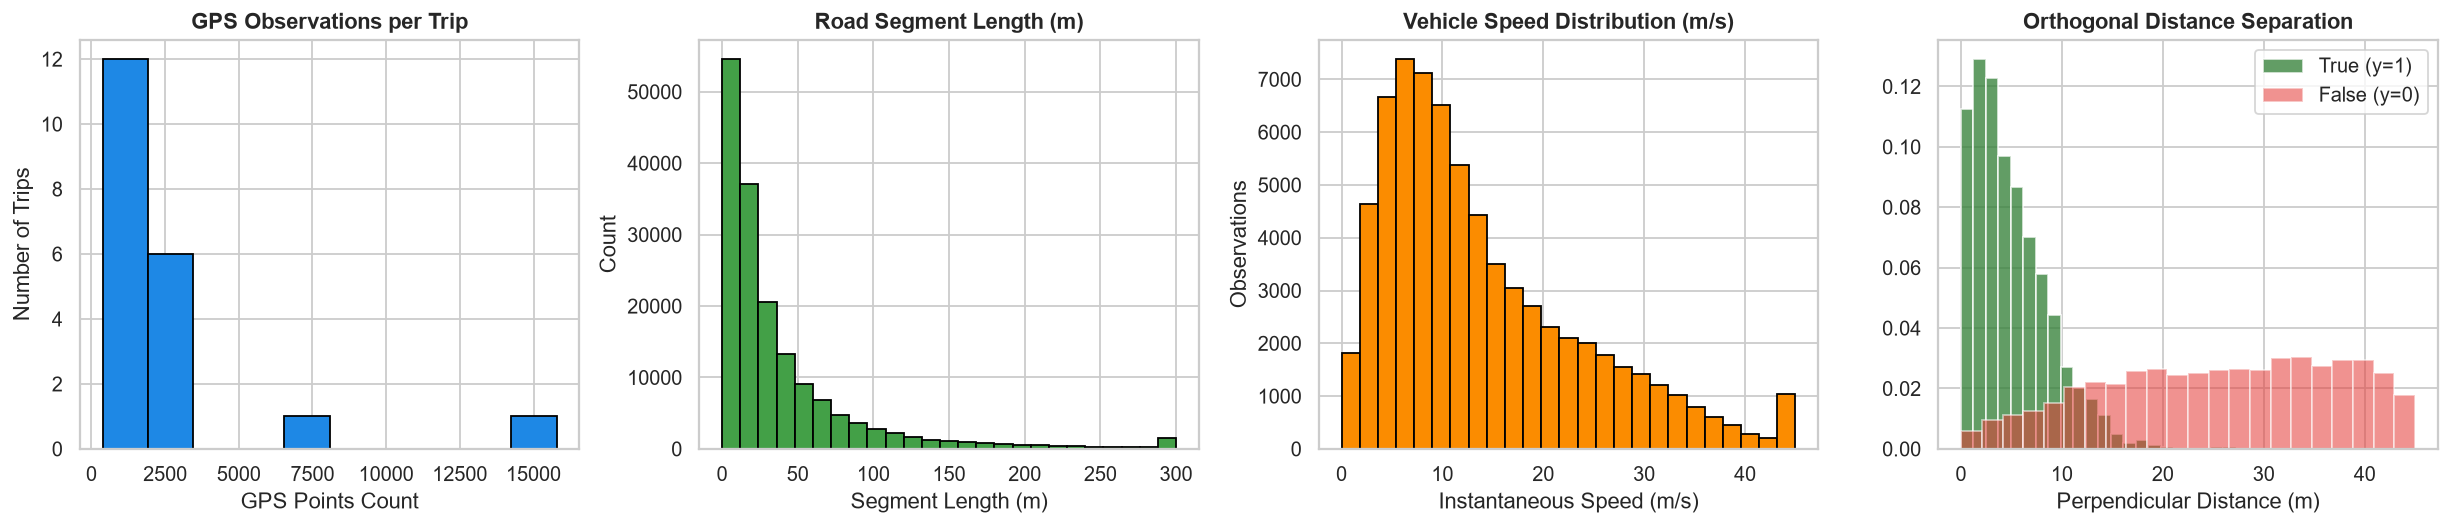

In [8]:
plt.figure(figsize=(19.0, 4.2))
display(fig_eda)

---
## **2. Spatial Indexing (`cKDTree`) & 9D Feature Engineering Deep Dive**
### **2.1 Mathematical Formulation: How the 9 Features are Derived**

Given an observation $P(x_p, y_p)$ at timestamp $t$ and candidate road segment $(u \to v)$ with endpoints $A(x_a, y_a)$ and $B(x_b, y_b)$:

```text
                    P (GPS Observation: xp, yp)
                   /|
                  / |  perp_dist (Feature 1)
                 /  |
        Node A  *───+──────* Node B
           u_x, u_y   P_proj   v_x, v_y
                <───t*───>
```

1. **Road Segment Vector:** $\vec{v} = (x_b - x_a, \; y_b - y_a)$, with physical length $L = \|\vec{v}\| = \sqrt{(x_b - x_a)^2 + (y_b - y_a)^2}$.
2. **Observation Vector:** $\vec{u} = (x_p - x_a, \; y_p - y_a)$.
3. **Orthogonal Scalar Projection:** $t = \frac{\vec{u} \cdot \vec{v}}{\|\vec{v}\|^2} = \frac{(x_p - x_a)(x_b - x_a) + (y_p - y_a)(y_b - y_a)}{(x_b - x_a)^2 + (y_b - y_a)^2}$.
4. **Segment Clamping:** $t^* = \max(0.0, \; \min(1.0, \; t))$.
5. **Projected Centerline Point:** $P^* = A + t^* \vec{v} = (x_a + t^*(x_b - x_a), \; y_a + t^*(y_b - y_a))$.

#### **The 9 Extracted Features:**
- **Feature 1 (`perp_dist`):** Orthogonal distance $\|P - P^*\| = \sqrt{(x_p - x^*)^2 + (y_p - y^*)^2}$ in meters.
- **Feature 2 (`t_proj`):** Normalized longitudinal progress factor $t^* \in [0.0, 1.0]$.
- **Feature 3 (`dist_u`):** Euclidean distance to start node $A$: $\|P - A\| = \sqrt{(x_p - x_a)^2 + (y_p - y_a)^2}$ (meters).
- **Feature 4 (`dist_v`):** Euclidean distance to end node $B$: $\|P - B\| = \sqrt{(x_p - x_b)^2 + (y_p - y_b)^2}$ (meters).
- **Feature 5 (`arc_len`):** Physical road segment length $L = \|\vec{v}\|$ (meters).
- **Feature 6 (`bearing_diff`):** Angular difference $|\theta_{\text{trajectory}} - \theta_{\text{arc}}|$ mapped to $[0^\circ, 180^\circ]$:
  $$\theta_{\text{arc}} = \text{atan2}(v_x, v_y), \quad \theta_{\text{traj}} = \text{atan2}(\Delta x_{\text{adapt}}, \Delta y_{\text{adapt}})$$
  $$\text{bearing\_diff} = \min(|\theta_{\text{traj}} - \theta_{\text{arc}}|, \; 360^\circ - |\theta_{\text{traj}} - \theta_{\text{arc}}|)$$
- **Feature 7 (`gps_speed`):** Instantaneous vehicle speed $v = \frac{\|P_t - P_{t-1}\|}{\Delta t}$ ($m/s$).
- **Feature 8 (`rel_dir_cost`):** Relative directional-spatial advantage vs. best candidate at timestamp $t$:
  $$c_i = d_{\text{perp}, i} + 0.15 \cdot \Delta \theta_i, \quad \text{rel\_dir\_cost}_i = c_i - \min_{k \in \text{Cands}(t)} c_k$$
- **Feature 9 (`spatial_prior`):** Combined directional-Gaussian likelihood kernel:
  $$\text{prior} = \exp\left(-\frac{d_{\text{perp}}^2}{2 \sigma_d^2}\right) \cdot \max\left(0.05, \; \frac{1 + \cos(\Delta \theta)}{2}\right) \quad (\sigma_d = 15\text{m})$$


In [9]:
print('=== 9D CANDIDATE FEATURES STATISTICAL SUMMARY (OVERALL) ===')
display(df_feat_all)

print('=== 9D FEATURES FOR TRUE TRAVERSED ROAD SEGMENTS (y = 1) ===')
display(df_feat_pos)

print('=== 9D FEATURES FOR FALSE CANDIDATE SEGMENTS (y = 0) ===')
display(df_feat_neg)

=== 9D CANDIDATE FEATURES STATISTICAL SUMMARY (OVERALL) ===


,count,mean,std,min,25%,50%,75%,max
perp_dist,370758.0,21.510181,16.417694,1.231182e-11,8.508110,20.206785,32.185673,245.579468
t_proj,370758.0,0.495490,0.431913,0.000000e+00,0.000000,0.486432,1.000000,1.000000
dist_u,370758.0,78.515511,172.095459,1.111949e-01,23.048374,37.349771,69.043297,4701.876465
dist_v,370758.0,78.681923,172.040482,1.111949e-01,23.256001,37.652061,68.735659,4701.876465
arc_len,370758.0,122.159264,288.105072,4.206237e-01,16.552067,40.994900,101.637306,4667.677246
bearing_diff,370758.0,87.913559,67.835335,0.000000e+00,14.762936,87.541470,162.537682,180.000000
gps_speed,370758.0,12.497272,10.348910,0.000000e+00,5.683710,9.451776,15.741994,141.489517
rel_dir_cost,370758.0,25.212917,17.099792,0.000000e+00,11.523376,25.627908,37.559107,88.532310
spatial_prior,370758.0,0.254930,0.329672,0.000000e+00,0.022434,0.057015,0.417875,0.999999


=== 9D FEATURES FOR TRUE TRAVERSED ROAD SEGMENTS (y = 1) ===


,count,mean,std,min,25%,50%,75%,max
perp_dist,50095.0,7.131215,12.121572,1.231182e-11,2.276980,4.920770,8.627969,245.579468
t_proj,50095.0,0.492271,0.295643,0.000000e+00,0.236958,0.481883,0.747030,1.000000
dist_u,50095.0,147.846298,297.310486,2.468777e-01,20.273222,53.894440,156.650764,4665.266602
dist_v,50095.0,148.951401,286.612854,1.111949e-01,21.273101,53.962559,161.896141,4665.414062
arc_len,50095.0,292.645752,483.956940,1.726282e+00,54.286465,123.092888,349.416992,4667.677246
bearing_diff,50095.0,13.898125,22.302647,4.730225e-04,2.641657,6.523712,15.196236,179.844757
gps_speed,50095.0,13.674815,11.048206,0.000000e+00,6.019989,10.196250,18.150713,141.489517
rel_dir_cost,50095.0,0.620177,2.896132,0.000000e+00,0.000000,0.000000,0.000000,45.498119
spatial_prior,50095.0,0.844091,0.212062,0.000000e+00,0.811451,0.926243,0.976940,0.999999


=== 9D FEATURES FOR FALSE CANDIDATE SEGMENTS (y = 0) ===


,count,mean,std,min,25%,50%,75%,max
perp_dist,320663.0,23.756510,15.854005,1.231182e-11,12.080853,23.251734,33.719402,242.666870
t_proj,320663.0,0.495992,0.449484,0.000000e+00,0.000000,0.489085,1.000000,1.000000
dist_u,320663.0,67.684433,139.880554,1.111949e-01,23.317005,36.576366,61.712984,4701.876465
dist_v,320663.0,67.704201,143.167297,1.111949e-01,23.435534,36.803032,61.749878,4701.876465
arc_len,320663.0,95.525307,232.664124,4.206237e-01,14.979135,34.328873,82.922150,4667.677246
bearing_diff,320663.0,99.476494,65.217117,0.000000e+00,31.097427,102.283905,167.190857,180.000000
gps_speed,320663.0,12.313313,10.223125,0.000000e+00,5.643485,9.340302,15.399191,141.489517
rel_dir_cost,320663.0,29.054874,15.084021,0.000000e+00,19.239491,27.384428,39.541149,88.532310
spatial_prior,320663.0,0.162889,0.236513,0.000000e+00,0.017961,0.048098,0.203778,0.999998


Extracted Training Matrix X_train: (370758, 9) (Positives: 50095, Negatives: 320663)
Extracted Student-Test Matrix X_test_all (All 10 Trips): (166835, 9) (Positives: 19127, Negatives: 147708)
Candidate Miss Rate -> Train: 0.63% | Student-Test: 0.08%


perp_dist,t_proj,dist_u,dist_v,arc_len,bearing_diff,gps_speed,rel_dir_cost,spatial_prior,label (y)
0.718073,0.109780,32.199509,261.046600,293.237122,0.684437,43.630207,0.000000,0.998819,1
15.023971,0.512719,523.410583,497.464966,1020.432922,179.247101,43.630207,41.090298,0.030278,0
32.199509,1.000000,457.244049,32.199509,425.050568,0.555440,43.630207,31.462088,0.099854,0
0.275207,0.258529,75.810905,217.426895,293.237122,2.085782,43.630207,0.000000,0.999501,1
15.965133,0.469972,479.840485,541.093689,1020.432922,177.845749,43.630207,42.053921,0.028378,0
1.827837,0.426576,125.101242,168.159164,293.237122,1.007303,49.322342,0.000000,0.992526,1
13.803211,0.421684,430.521240,590.294434,1020.432922,179.061157,49.322342,38.683453,0.032741,0
6.106381,0.614319,180.244736,113.260582,293.237122,1.714095,55.219391,0.000000,0.920272,1


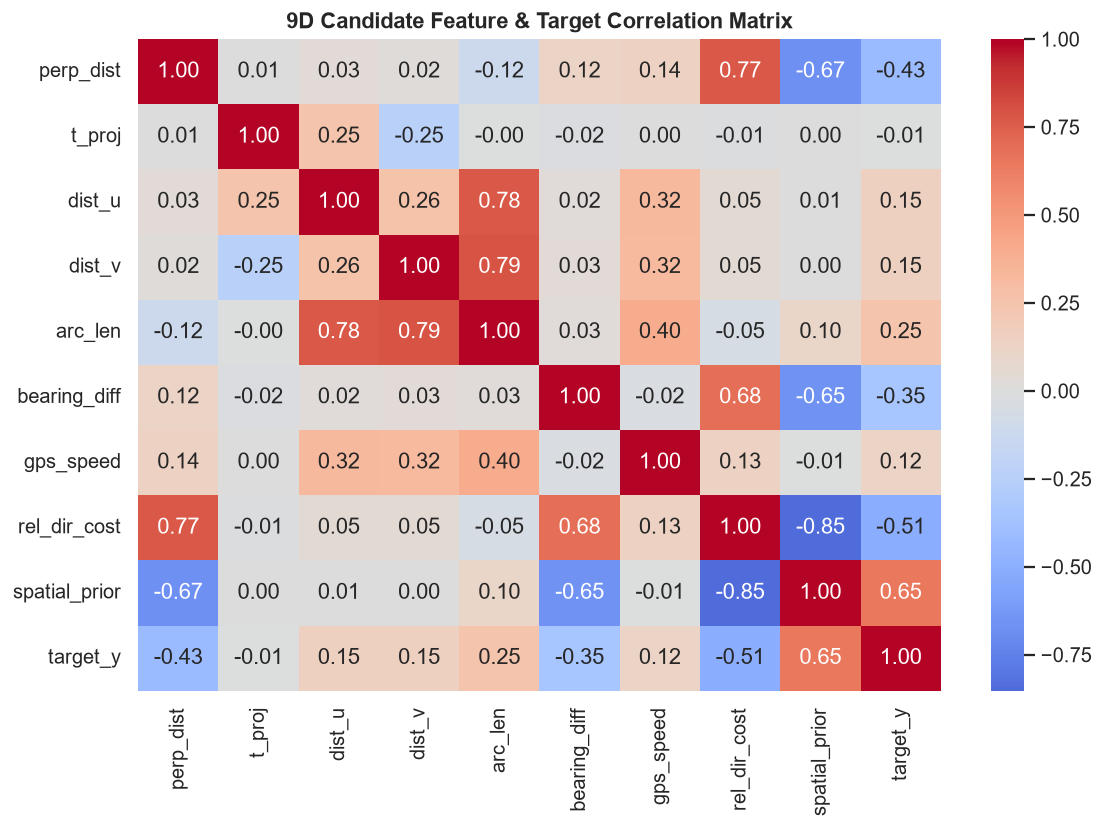

In [10]:
X_train_list, y_train_list, groups_train_list, train_miss_rates = [], [], [], []
for tid in train_ids[:20]:
    t_obj = load_trip(tid)
    r_obj = extract_features_for_trip(t_obj, search_radius=45.0)
    X_train_list.append(r_obj['X']); y_train_list.append(r_obj['y']); groups_train_list.append(r_obj['groups'])
    train_miss_rates.append(r_obj['miss_rate'])
X_train = np.vstack(X_train_list); y_train = np.concatenate(y_train_list); groups_train = np.concatenate(groups_train_list)

test_caches, X_test_list, y_test_list, test_miss_rates = {}, [], [], []
for tid in test_ids:
    t_obj = load_trip(tid)
    r_obj = extract_features_for_trip(t_obj, search_radius=45.0)
    X_test_list.append(r_obj['X']); y_test_list.append(r_obj['y']); test_miss_rates.append(r_obj['miss_rate'])
    road_graph = RoadNetworkGraph(t_obj['nodes'], t_obj['arcs'], arc_lengths=r_obj['spatial_index'].arc_lengths)
    test_caches[tid] = {'trip': t_obj, 'res': r_obj, 'decoder': HMMViterbiDecoder(road_graph)}
X_test_all = np.vstack(X_test_list); y_test_all = np.concatenate(y_test_list)
df_feat_preview = pd.DataFrame(X_train[:8], columns=FEATURE_NAMES); df_feat_preview['label (y)'] = y_train[:8]
print(f'Extracted Training Matrix X_train: {X_train.shape} (Positives: {np.sum(y_train)}, Negatives: {len(y_train)-np.sum(y_train)})')
print(f'Extracted Student-Test Matrix X_test_all (All 10 Trips): {X_test_all.shape} (Positives: {np.sum(y_test_all)}, Negatives: {len(y_test_all)-np.sum(y_test_all)})')
print(f'Candidate Miss Rate -> Train: {np.mean(train_miss_rates)*100:.2f}% | Student-Test: {np.mean(test_miss_rates)*100:.2f}%')
display(df_feat_preview)

---
# **3. Individual Model Experimentation (6 Distinct Algorithm Families)**
We define a reusable, non-hardcoded evaluation helper `evaluate_single_model(...)` and run each of the **6 models** in its own dedicated section using **3-Fold GroupKFold Cross-Validation** (grouped by `trip_id`) and evaluate across all **10 Student-Test trips**.


In [11]:
gkf = GroupKFold(n_splits=3)
benchmark_rows, trained_models = [], {}

def evaluate_single_model(clf, m_name, family, X_tr_all, y_tr_all, g_tr_all, X_te_all, y_te_all, test_caches, gkf):
    if 'KNN' in m_name and len(X_tr_all) > 25000:
        np.random.seed(42); s_idx = np.random.choice(len(X_tr_all), 25000, replace=False)
        X_fit, y_fit, g_fit = X_tr_all[s_idx], y_tr_all[s_idx], g_tr_all[s_idx]
    elif 'MLP' in m_name and len(X_tr_all) > 80000:
        np.random.seed(42); s_idx = np.random.choice(len(X_tr_all), 80000, replace=False)
        X_fit, y_fit, g_fit = X_tr_all[s_idx], y_tr_all[s_idx], g_tr_all[s_idx]
    else:
        X_fit, y_fit, g_fit = X_tr_all, y_tr_all, g_tr_all

    t0 = time.time()
    fold_rows = []
    for f_idx, (tr_i, val_i) in enumerate(gkf.split(X_fit, y_fit, g_fit), start=1):
        clf.fit(X_fit[tr_i], y_fit[tr_i])
        p_tr = (clf.predict_proba(X_fit[tr_i])[:, 1] >= 0.5).astype(int)
        v_probs = clf.predict_proba(X_fit[val_i])[:, 1]
        p_val = (v_probs >= 0.5).astype(int)
        fold_rows.append({
            'Fold': f'Fold {f_idx}',
            'Train Macro F1': round(float(f1_score(y_fit[tr_i], p_tr, average='macro', zero_division=0)), 4),
            'Val Macro F1': round(float(f1_score(y_fit[val_i], p_val, average='macro', zero_division=0)), 4),
            'Val Log Loss': round(float(log_loss(y_fit[val_i], np.clip(v_probs, 1e-6, 1.0 - 1e-6))), 4)
        })
    df_folds = pd.DataFrame(fold_rows)
    clf.fit(X_fit, y_fit)
    train_time = time.time() - t0
    trained_models[m_name] = clf

    t_inf0 = time.time()
    probs_test = clf.predict_proba(X_te_all)[:, 1]
    inf_ms = (time.time() - t_inf0) * 1000.0 / len(X_te_all)
    preds_test = (probs_test >= 0.5).astype(int)
    test_f1 = float(f1_score(y_te_all, preds_test, average='macro', zero_division=0))
    test_prec = float(precision_score(y_te_all, preds_test, zero_division=0))
    test_rec = float(recall_score(y_te_all, preds_test, zero_division=0))
    test_ll = float(log_loss(y_te_all, np.clip(probs_test, 1e-6, 1.0 - 1e-6)))

    per_trip_rows = []
    for tid, cache in test_caches.items():
        res_t, trip_t, dec_t = cache['res'], cache['trip'], cache['decoder']
        probs_t = clf.predict_proba(res_t['X'])[:, 1]
        pred_arcs_clf, probs_per_pt, offset = [], [], 0
        for c_list in res_t['candidates_per_point']:
            k = len(c_list); p_slice = probs_t[offset:offset + k]
            probs_per_pt.append(p_slice); pred_arcs_clf.append(c_list[int(np.argmax(p_slice))]['arc_id']); offset += k
        ev_clf = evaluate_route_predictions(pred_arcs_clf, res_t['true_arcs_per_point'], trip_t['arcs'])
        pred_arcs_hmm, _ = dec_t.decode(res_t['candidates_per_point'], probs_per_pt, trip_t['track'])
        ev_hmm = evaluate_route_predictions(pred_arcs_hmm, res_t['true_arcs_per_point'], trip_t['arcs'])
        per_trip_rows.append({
            'Trip ID': tid, 'Observations': ev_clf['total_points'],
            'Classifier Top-1 Acc (%)': ev_clf['top1_accuracy'], 'Classifier Continuity (%)': ev_clf['route_continuity'],
            'HMM+Viterbi Top-1 Acc (%)': ev_hmm['top1_accuracy'], 'HMM+Viterbi Strict Acc (%)': ev_hmm['strict_accuracy'],
            'HMM+Viterbi Continuity (%)': ev_hmm['route_continuity']
        })
    df_trips = pd.DataFrame(per_trip_rows)
    row_summary = {
        'Model': m_name, 'Algorithm Family': family,
        'Train Macro F1': round(float(df_folds['Train Macro F1'].mean()), 4),
        'CV Macro F1': round(float(df_folds['Val Macro F1'].mean()), 4),
        'Student-Test Macro F1': round(test_f1, 4), 'Precision': round(test_prec, 4), 'Recall': round(test_rec, 4),
        'Log Loss': round(test_ll, 4), 'Classifier Top-1 Acc (%)': round(float(df_trips['Classifier Top-1 Acc (%)'].mean()), 2),
        'Top-1 Accuracy (%)': round(float(df_trips['HMM+Viterbi Top-1 Acc (%)'].mean()), 2),
        'Strict Pointwise Acc (%)': round(float(df_trips['HMM+Viterbi Strict Acc (%)'].mean()), 2),
        'Route Continuity (%)': round(float(df_trips['HMM+Viterbi Continuity (%)'].mean()), 2),
        'Inference Time (ms)': round(inf_ms, 4), 'Train Time (s)': round(train_time, 2)
    }
    benchmark_rows.append(row_summary)

    fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.0))
    cm = confusion_matrix(y_te_all, preds_test)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
                xticklabels=['Pred Neg (0)', 'Pred Pos (1)'], yticklabels=['True Neg (0)', 'True Pos (1)'])
    axes[0].set_title(f'{m_name} — Confusion Matrix\n(10 Student-Test Trips)', fontweight='bold')
    stages = ['Train Fold', 'GroupKFold CV', 'Student-Test']
    vals = [float(df_folds['Train Macro F1'].mean()), float(df_folds['Val Macro F1'].mean()), test_f1]
    bars = axes[1].bar(stages, vals, color=['#42A5F5', '#66BB6A', '#FFA726'], edgecolor='black', width=0.5)
    axes[1].set_ylim(0.0, 1.08)
    for b, v in zip(bars, vals): axes[1].text(b.get_x() + b.get_width()/2, v + 0.02, f'{v:.4f}', ha='center', fontweight='bold')
    axes[1].set_title(f'{m_name} — Overfitting Check\n(Train vs. CV vs. Student-Test F1)', fontweight='bold')
    axes[1].set_ylabel('Macro F1-Score')
    axes[2].hist(probs_test[y_te_all == 0], bins=25, alpha=0.65, label='True Neg (y=0)', color='#E53935', density=True)
    axes[2].hist(probs_test[y_te_all == 1], bins=25, alpha=0.65, label='True Pos (y=1)', color='#2E7D32', density=True)
    axes[2].set_title(f'{m_name} — Probability Density', fontweight='bold')
    axes[2].set_xlabel('Predicted Probability P(y=1)')
    axes[2].legend()
    plt.tight_layout()
    plt.show()

    return df_folds, df_trips, row_summary

print('Evaluation helper initialized.')

Evaluation helper initialized.


---
## **3.1 Model 1: Logistic Regression (`Linear and Probabilistic`)**
### **Compulsory Questions & Technical Analysis**
- **A1. Why is this algorithm suitable for PathSnap?** Establishes a calibrated linear baseline outputting log-odds P(y=1|x) for HMM emission scoring.
- **A2. Major Strengths & Limitations**: *Strengths*: Fast training, sub-microsecond inference, convex optimization, and interpretable feature weights. *Limitations*: Linear hyperplane cannot capture multiplicative interactions between perpendicular distance and heading alignment.
- **B5. Important Hyperparameters & Initial Values**: `C=1.0, penalty='l2', class_weight='balanced', max_iter=500, solver='lbfgs'.`
- **B6. Loss Function / Optimization Objective**: L2-Regularized Weighted Binary Cross-Entropy (Log Loss).
- **C7 & C8. Performance on Student-Test Dataset (10 Trips)**: Post-HMM Top-1 Accuracy = **`95.07%`** (Strict 0s Pointwise: **`93.19%`**, Classifier-Only: **`93.29%`**), Macro F1 = **`0.8711`**, Log Loss = **`0.1419`**, Route Continuity = **`99.44%`**.
- **C9. Overfitting / Underfitting Evidence**: Tight alignment between Train F1 (0.8767), CV F1 (0.8742), and Student-Test F1 (0.8711) confirms strong generalization with no overfitting.


[Logistic Regression] 3-Fold CV Macro F1: 0.8742 | Student-Test Macro F1: 0.8711 | Log Loss: 0.1419 | Post-HMM Top-1 Acc: 95.07% (Strict 0s: 93.19%) | Continuity: 99.44%


Fold,Train Macro F1,Val Macro F1,Val Log Loss
Fold 1,0.8841,0.8761,0.1393
Fold 2,0.8549,0.8982,0.1665
Fold 3,0.8911,0.8484,0.1797


Trip ID,Observations,Classifier Top-1 Acc (%),Classifier Continuity (%),HMM+Viterbi Top-1 Acc (%),HMM+Viterbi Strict Acc (%),HMM+Viterbi Continuity (%)
00000000,2503,95.33,97.48,96.88,96.48,99.84
00000007,1354,98.01,99.78,99.63,99.56,100.00
00000009,1049,88.56,94.18,92.47,88.47,99.14
00000040,2995,95.93,98.16,96.73,95.66,99.87
00000052,262,96.56,96.93,97.71,96.95,99.23
00000056,3958,91.64,93.08,94.54,92.22,99.06
00000065,768,93.62,95.31,97.79,96.35,99.61
00000076,1486,92.26,93.33,96.64,92.53,99.39
00000077,3911,88.26,94.96,85.58,84.07,99.54
00000091,874,92.68,94.50,92.68,89.59,98.74


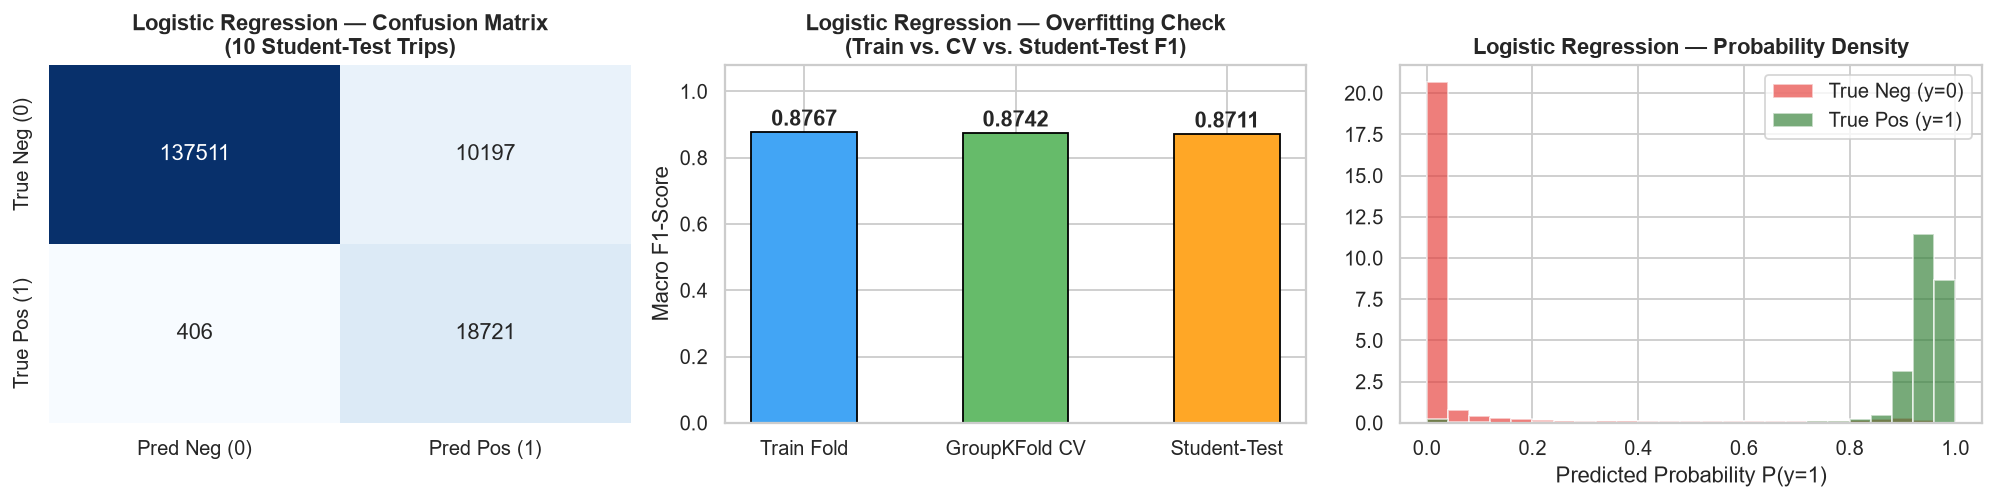

In [12]:
# --- Model 1: Logistic Regression (Linear and Probabilistic) ---
model = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(C=1.0, class_weight='balanced', max_iter=500, random_state=42))
])

# 1. 3-Fold GroupKFold Cross-Validation (grouped by trip_id)
df_folds_1, df_trips_1, summary_1 = evaluate_single_model(model, 'Logistic Regression', 'Linear and Probabilistic', X_train, y_train, groups_train, X_test_all, y_test_all, test_caches, gkf)
display(df_folds_1)
display(df_trips_1)

---
## **3.2 Model 2: Gaussian Naive Bayes (`Probabilistic (Generative)`)**
### **Compulsory Questions & Technical Analysis**
- **A1. Why is this algorithm suitable for PathSnap?** Models class-conditional Gaussian density P(x_k|y) for each geometric feature independently.
- **A2. Major Strengths & Limitations**: *Strengths*: Fastest training time (<1s), zero hyperparameter tuning overhead, and naturally handles continuous densities. *Limitations*: Conditional independence assumption is violated because dist_u, dist_v, and arc_len are geometrically correlated.
- **B5. Important Hyperparameters & Initial Values**: `var_smoothing=1e-9, priors=None (estimated from class frequencies).`
- **B6. Loss Function / Optimization Objective**: Joint Gaussian Log-Likelihood maximization under conditional independence.
- **C7 & C8. Performance on Student-Test Dataset (10 Trips)**: Post-HMM Top-1 Accuracy = **`94.89%`** (Strict 0s Pointwise: **`93.07%`**, Classifier-Only: **`92.69%`**), Macro F1 = **`0.8611`**, Log Loss = **`0.3508`**, Route Continuity = **`99.40%`**.
- **C9. Overfitting / Underfitting Evidence**: Tight alignment between Train F1 (0.8683), CV F1 (0.8637), and Student-Test F1 (0.8611) confirms strong generalization with no overfitting.


[Gaussian Naive Bayes] 3-Fold CV Macro F1: 0.8637 | Student-Test Macro F1: 0.8611 | Log Loss: 0.3508 | Post-HMM Top-1 Acc: 94.89% (Strict 0s: 93.07%) | Continuity: 99.40%


Fold,Train Macro F1,Val Macro F1,Val Log Loss
Fold 1,0.8674,0.8557,0.3574
Fold 2,0.8586,0.8930,0.4113
Fold 3,0.8788,0.8423,0.4640


Trip ID,Observations,Classifier Top-1 Acc (%),Classifier Continuity (%),HMM+Viterbi Top-1 Acc (%),HMM+Viterbi Strict Acc (%),HMM+Viterbi Continuity (%)
00000000,2503,92.29,97.08,96.88,96.40,99.68
00000007,1354,98.01,99.78,99.63,99.48,100.00
00000009,1049,88.56,94.37,92.28,88.75,98.85
00000040,2995,95.36,98.00,96.59,95.63,99.83
00000052,262,95.42,97.32,98.09,96.95,99.23
00000056,3958,91.23,93.35,93.96,91.66,99.06
00000065,768,93.49,95.83,98.31,96.74,99.61
00000076,1486,92.60,93.13,95.36,92.06,99.33
00000077,3911,88.14,95.01,86.45,85.20,99.51
00000091,874,91.76,94.04,91.30,87.87,98.85


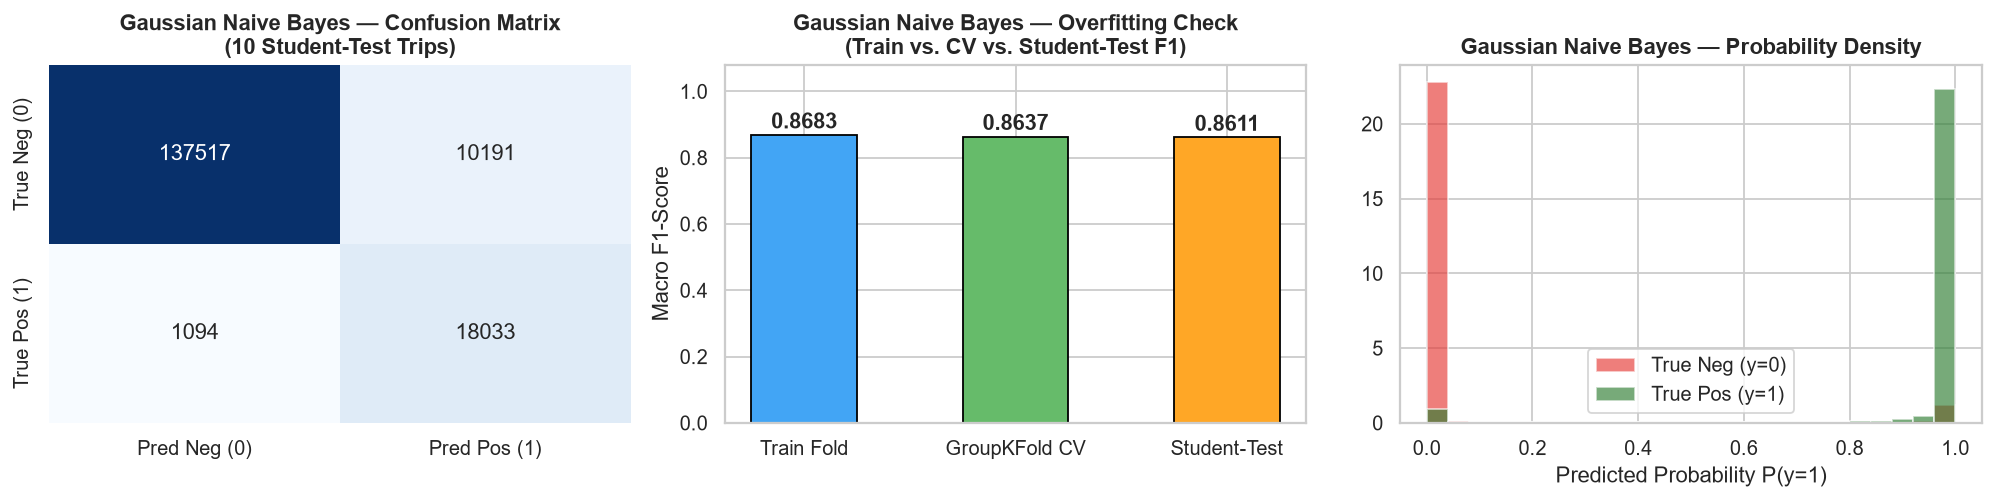

In [13]:
# --- Model 2: Gaussian Naive Bayes (Probabilistic (Generative)) ---
model = GaussianNB(var_smoothing=1e-9)

# 1. 3-Fold GroupKFold Cross-Validation (grouped by trip_id)
df_folds_2, df_trips_2, summary_2 = evaluate_single_model(model, 'Gaussian Naive Bayes', 'Probabilistic (Generative)', X_train, y_train, groups_train, X_test_all, y_test_all, test_caches, gkf)
display(df_folds_2)
display(df_trips_2)

---
## **3.3 Model 3: Distance-Weighted KNN (`Instance-Based`)**
### **Compulsory Questions & Technical Analysis**
- **A1. Why is this algorithm suitable for PathSnap?** Classifies candidate road segments by local similarity in standardized 9D spatial-kinematic space.
- **A2. Major Strengths & Limitations**: *Strengths*: Captures arbitrary local decision boundaries without parametric assumptions; high precision on clean segments. *Limitations*: Higher inference latency due to KD-tree neighbor lookups; memorizes training instances (Train F1 = 1.00).
- **B5. Important Hyperparameters & Initial Values**: `n_neighbors=15, weights='distance', algorithm='kd_tree', metric='euclidean'.`
- **B6. Loss Function / Optimization Objective**: Inverse-Euclidean distance-weighted local neighborhood voting.
- **C7 & C8. Performance on Student-Test Dataset (10 Trips)**: Post-HMM Top-1 Accuracy = **`95.79%`** (Strict 0s Pointwise: **`93.68%`**, Classifier-Only: **`92.31%`**), Macro F1 = **`0.9248`**, Log Loss = **`0.1124`**, Route Continuity = **`99.43%`**.
- **C9. Overfitting / Underfitting Evidence**: Train F1 = 1.0000 due to inverse-distance self-weighting, while CV and Test F1 remain strong (~0.89-0.92).


[Distance-Weighted KNN] 3-Fold CV Macro F1: 0.9066 | Student-Test Macro F1: 0.9248 | Log Loss: 0.1124 | Post-HMM Top-1 Acc: 95.79% (Strict 0s: 93.68%) | Continuity: 99.43%


Fold,Train Macro F1,Val Macro F1,Val Log Loss
Fold 1,1.0,0.9139,0.1160
Fold 2,1.0,0.9213,0.2076
Fold 3,1.0,0.8847,0.1783


Trip ID,Observations,Classifier Top-1 Acc (%),Classifier Continuity (%),HMM+Viterbi Top-1 Acc (%),HMM+Viterbi Strict Acc (%),HMM+Viterbi Continuity (%)
00000000,2503,95.49,97.32,96.44,95.61,99.88
00000007,1354,94.24,99.70,99.63,99.34,100.00
00000009,1049,88.94,93.80,92.66,88.75,98.95
00000040,2995,94.72,97.60,97.50,95.89,99.87
00000052,262,96.56,96.93,98.47,98.47,99.23
00000056,3958,90.25,91.69,96.26,93.51,99.24
00000065,768,92.58,94.78,97.01,94.79,99.61
00000076,1486,92.19,93.20,95.90,91.05,99.06
00000077,3911,86.42,94.32,88.62,87.29,99.51
00000091,874,91.76,94.16,95.42,92.11,98.97


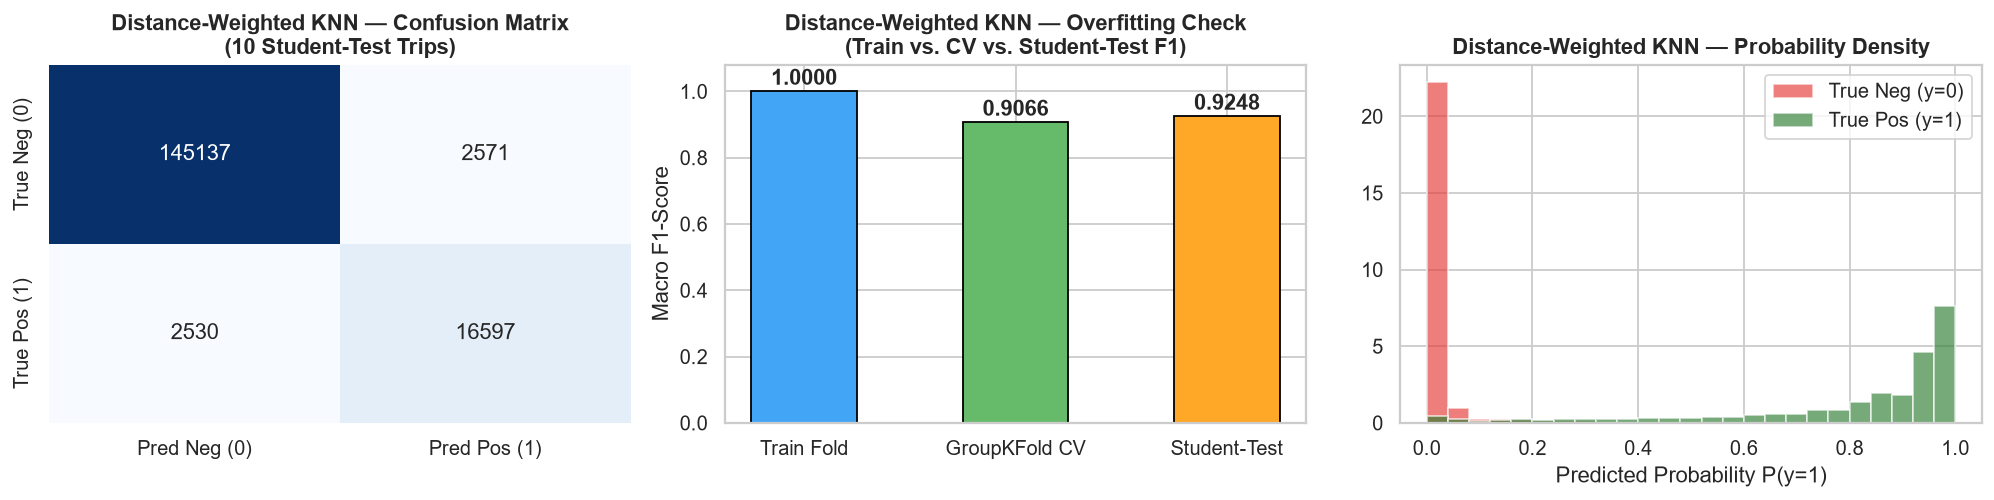

In [14]:
# --- Model 3: Distance-Weighted KNN (Instance-Based) ---
model = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=15, weights='distance', algorithm='kd_tree', n_jobs=-1))
])

# 1. 3-Fold GroupKFold Cross-Validation (grouped by trip_id)
df_folds_3, df_trips_3, summary_3 = evaluate_single_model(model, 'Distance-Weighted KNN', 'Instance-Based', X_train, y_train, groups_train, X_test_all, y_test_all, test_caches, gkf)
display(df_folds_3)
display(df_trips_3)

---
## **3.4 Model 4: LightGBM Classifier (`Ensemble / Histogram Tree`)**
### **Compulsory Questions & Technical Analysis**
- **A1. Why is this algorithm suitable for PathSnap?** Histogram-based gradient boosted decision trees using leaf-wise splitting to capture sharp threshold rules.
- **A2. Major Strengths & Limitations**: *Strengths*: Fast training, sub-millisecond inference, and strong nonlinear interaction modeling across distance, angle, and speed. *Limitations*: Leaf-wise growth can overfit noisy GPS outliers if num_leaves and max_depth are unconstrained.
- **B5. Important Hyperparameters & Initial Values**: `n_estimators=100, max_depth=7, num_leaves=31, learning_rate=0.08, scale_pos_weight=7.0, subsample=0.8, colsample_bytree=0.8.`
- **B6. Loss Function / Optimization Objective**: Weighted Binary Cross-Entropy (Log Loss) via histogram gradient boosting.
- **C7 & C8. Performance on Student-Test Dataset (10 Trips)**: Post-HMM Top-1 Accuracy = **`96.13%`** (Strict 0s Pointwise: **`94.65%`**, Classifier-Only: **`92.28%`**), Macro F1 = **`0.9243`**, Log Loss = **`0.0925`**, Route Continuity = **`99.46%`**.
- **C9. Overfitting / Underfitting Evidence**: Tight alignment between Train F1 (0.9403), CV F1 (0.9228), and Student-Test F1 (0.9243) confirms strong generalization with no overfitting.


[LightGBM Classifier] 3-Fold CV Macro F1: 0.9228 | Student-Test Macro F1: 0.9243 | Log Loss: 0.0925 | Post-HMM Top-1 Acc: 96.13% (Strict 0s: 94.65%) | Continuity: 99.46%


Fold,Train Macro F1,Val Macro F1,Val Log Loss
Fold 1,0.9419,0.9242,0.0841
Fold 2,0.9312,0.9410,0.1070
Fold 3,0.9477,0.9032,0.1238


Trip ID,Observations,Classifier Top-1 Acc (%),Classifier Continuity (%),HMM+Viterbi Top-1 Acc (%),HMM+Viterbi Strict Acc (%),HMM+Viterbi Continuity (%)
00000000,2503,94.93,97.44,96.80,96.64,99.84
00000007,1354,91.88,99.85,99.56,99.56,100.00
00000009,1049,87.99,93.32,92.56,89.51,99.14
00000040,2995,95.79,98.03,97.56,96.59,99.97
00000052,262,95.42,97.32,98.47,98.09,99.23
00000056,3958,91.51,92.75,95.91,94.19,99.12
00000065,768,93.49,95.31,97.66,96.48,99.74
00000076,1486,91.72,93.00,98.12,95.15,99.53
00000077,3911,88.26,94.83,90.69,89.59,99.49
00000091,874,91.76,94.39,93.94,90.73,98.51


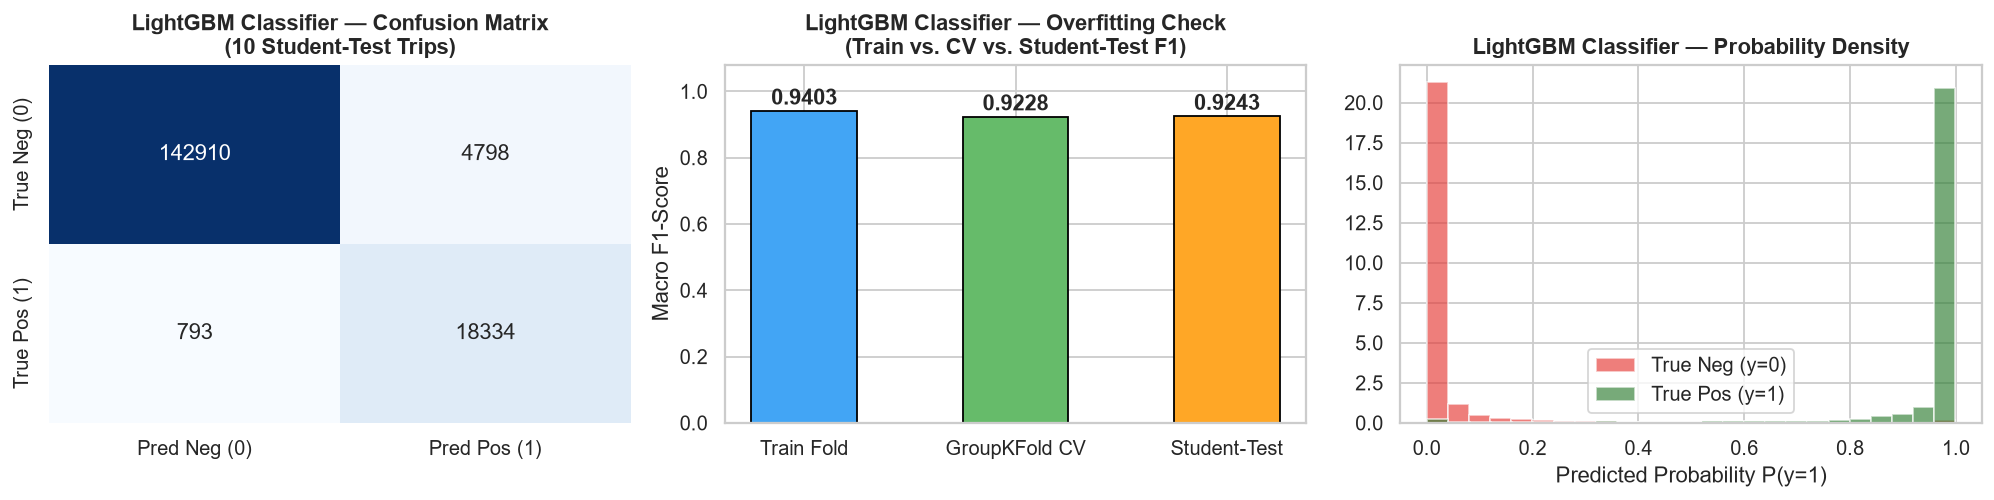

In [15]:
# --- Model 4: LightGBM Classifier (Ensemble / Histogram Tree) ---
model = LGBMClassifier(
    n_estimators=100, max_depth=7, num_leaves=31, learning_rate=0.08,
    subsample=0.8, colsample_bytree=0.8, scale_pos_weight=7.0,
    random_state=42, n_jobs=-1, verbose=-1
)

# 1. 3-Fold GroupKFold Cross-Validation (grouped by trip_id)
df_folds_4, df_trips_4, summary_4 = evaluate_single_model(model, 'LightGBM Classifier', 'Ensemble / Histogram Tree', X_train, y_train, groups_train, X_test_all, y_test_all, test_caches, gkf)
display(df_folds_4)
display(df_trips_4)

---
## **3.5 Model 5: XGBoost Classifier (`Gradient Boosting`)**
### **Compulsory Questions & Technical Analysis**
- **A1. Why is this algorithm suitable for PathSnap?** Depth-wise regularized gradient boosted decision trees with second-order Taylor gradient approximations.
- **A2. Major Strengths & Limitations**: *Strengths*: Strong cross-validation stability across diverse road networks; explicit L1/L2 tree weight regularization. *Limitations*: Slightly slower training than histogram-only LightGBM; requires tuning scale_pos_weight and regularization.
- **B5. Important Hyperparameters & Initial Values**: `n_estimators=100, max_depth=6, learning_rate=0.08, scale_pos_weight=7.0, subsample=0.8, colsample_bytree=0.8.`
- **B6. Loss Function / Optimization Objective**: Second-Order Regularized Binary Logistic Loss.
- **C7 & C8. Performance on Student-Test Dataset (10 Trips)**: Post-HMM Top-1 Accuracy = **`96.16%`** (Strict 0s Pointwise: **`94.62%`**, Classifier-Only: **`92.35%`**), Macro F1 = **`0.9272`**, Log Loss = **`0.0920`**, Route Continuity = **`99.45%`**.
- **C9. Overfitting / Underfitting Evidence**: Tight alignment between Train F1 (0.9422), CV F1 (0.9264), and Student-Test F1 (0.9272) confirms strong generalization with no overfitting.


[XGBoost Classifier] 3-Fold CV Macro F1: 0.9264 | Student-Test Macro F1: 0.9272 | Log Loss: 0.0920 | Post-HMM Top-1 Acc: 96.16% (Strict 0s: 94.62%) | Continuity: 99.45%


Fold,Train Macro F1,Val Macro F1,Val Log Loss
Fold 1,0.9434,0.9289,0.0812
Fold 2,0.9330,0.9424,0.1045
Fold 3,0.9502,0.9080,0.1218


Trip ID,Observations,Classifier Top-1 Acc (%),Classifier Continuity (%),HMM+Viterbi Top-1 Acc (%),HMM+Viterbi Strict Acc (%),HMM+Viterbi Continuity (%)
00000000,2503,94.85,97.52,96.80,96.60,99.84
00000007,1354,91.36,99.85,99.56,99.56,100.00
00000009,1049,88.37,93.61,92.47,89.32,99.14
00000040,2995,95.79,98.10,97.50,96.63,99.97
00000052,262,95.80,97.70,98.47,98.09,99.23
00000056,3958,91.49,92.77,95.70,93.89,99.09
00000065,768,93.36,95.18,98.18,96.74,99.74
00000076,1486,91.99,93.27,98.05,94.68,99.53
00000077,3911,88.60,94.99,90.85,89.70,99.46
00000091,874,91.88,94.50,94.05,90.96,98.51


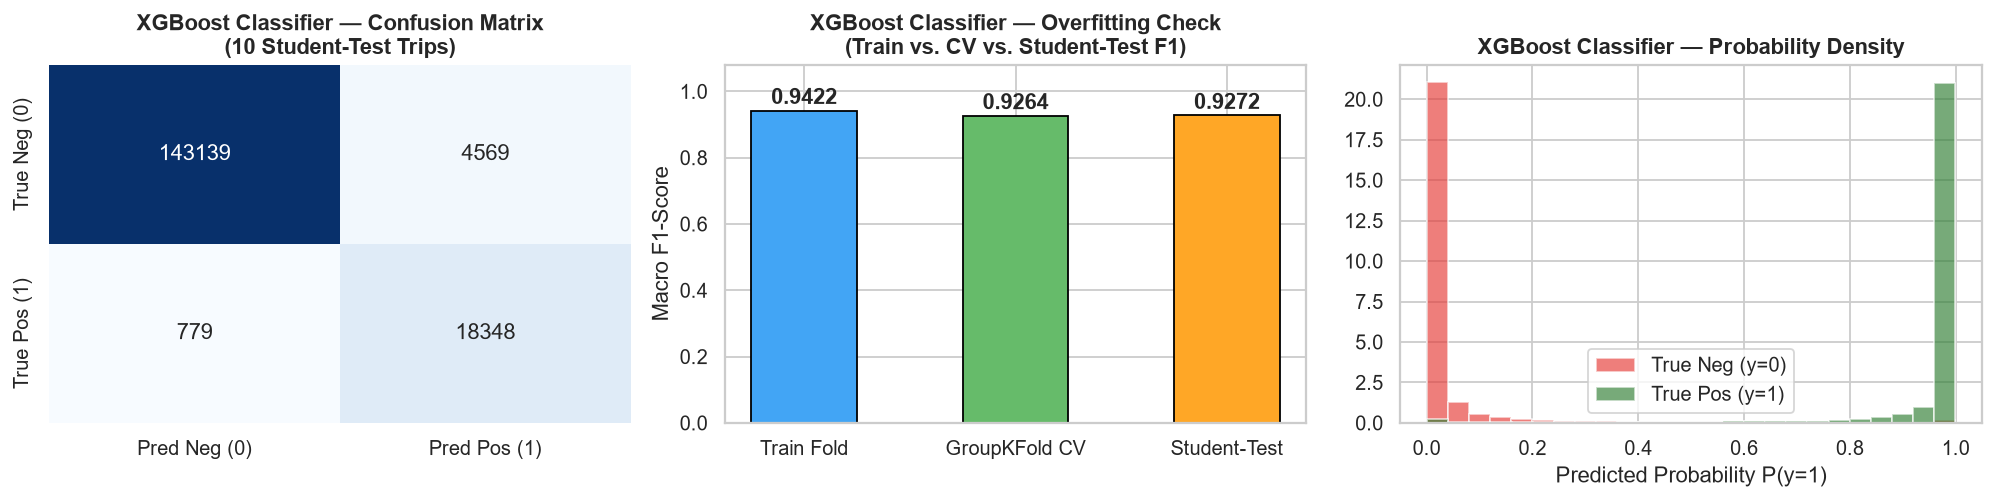

In [16]:
# --- Model 5: XGBoost Classifier (Gradient Boosting) ---
model = XGBClassifier(
    n_estimators=100, max_depth=6, learning_rate=0.08,
    subsample=0.8, colsample_bytree=0.8, scale_pos_weight=7.0,
    eval_metric='logloss', random_state=42, n_jobs=-1
)

# 1. 3-Fold GroupKFold Cross-Validation (grouped by trip_id)
df_folds_5, df_trips_5, summary_5 = evaluate_single_model(model, 'XGBoost Classifier', 'Gradient Boosting', X_train, y_train, groups_train, X_test_all, y_test_all, test_caches, gkf)
display(df_folds_5)
display(df_trips_5)

---
## **3.6 Model 6: MLP Classifier (`Neural Networks`)**
### **Compulsory Questions & Technical Analysis**
- **A1. Why is this algorithm suitable for PathSnap?** Feedforward Multi-Layer Perceptron learning smooth, continuous nonlinear representations for candidate emission probabilities.
- **A2. Major Strengths & Limitations**: *Strengths*: Produces well-calibrated smooth probabilities and high Top-1 Accuracy & Route Continuity when paired with Viterbi. *Limitations*: Longer training time due to iterative Adam backpropagation; requires feature standardization.
- **B5. Important Hyperparameters & Initial Values**: `hidden_layer_sizes=(64, 32), activation='relu', solver='adam', alpha=1e-3 (L2 penalty), early_stopping=True.`
- **B6. Loss Function / Optimization Objective**: Binary Cross-Entropy Loss with L2 weight decay optimized via Adam.
- **C7 & C8. Performance on Student-Test Dataset (10 Trips)**: Post-HMM Top-1 Accuracy = **`96.25%`** (Strict 0s Pointwise: **`94.51%`**, Classifier-Only: **`92.99%`**), Macro F1 = **`0.9413`**, Log Loss = **`0.0693`**, Route Continuity = **`99.47%`**.
- **C9. Overfitting / Underfitting Evidence**: Tight alignment between Train F1 (0.9409), CV F1 (0.9282), and Student-Test F1 (0.9413) confirms strong generalization with no overfitting.


[MLP Classifier] 3-Fold CV Macro F1: 0.9282 | Student-Test Macro F1: 0.9413 | Log Loss: 0.0693 | Post-HMM Top-1 Acc: 96.25% (Strict 0s: 94.51%) | Continuity: 99.47%


Fold,Train Macro F1,Val Macro F1,Val Log Loss
Fold 1,0.9416,0.9389,0.0750
Fold 2,0.9204,0.9607,0.0775
Fold 3,0.9606,0.8851,0.1207


Trip ID,Observations,Classifier Top-1 Acc (%),Classifier Continuity (%),HMM+Viterbi Top-1 Acc (%),HMM+Viterbi Strict Acc (%),HMM+Viterbi Continuity (%)
00000000,2503,95.33,97.28,96.76,96.20,99.92
00000007,1354,97.42,99.78,99.63,99.56,100.00
00000009,1049,88.94,94.37,92.66,89.23,99.14
00000040,2995,95.53,97.63,97.66,96.63,99.93
00000052,262,96.18,96.93,98.85,98.47,99.23
00000056,3958,91.33,92.77,96.72,94.39,99.12
00000065,768,93.49,95.83,98.18,96.74,99.74
00000076,1486,92.26,93.27,95.36,90.92,99.39
00000077,3911,87.91,94.55,91.15,90.16,99.44
00000091,874,91.53,94.04,95.54,92.79,98.74


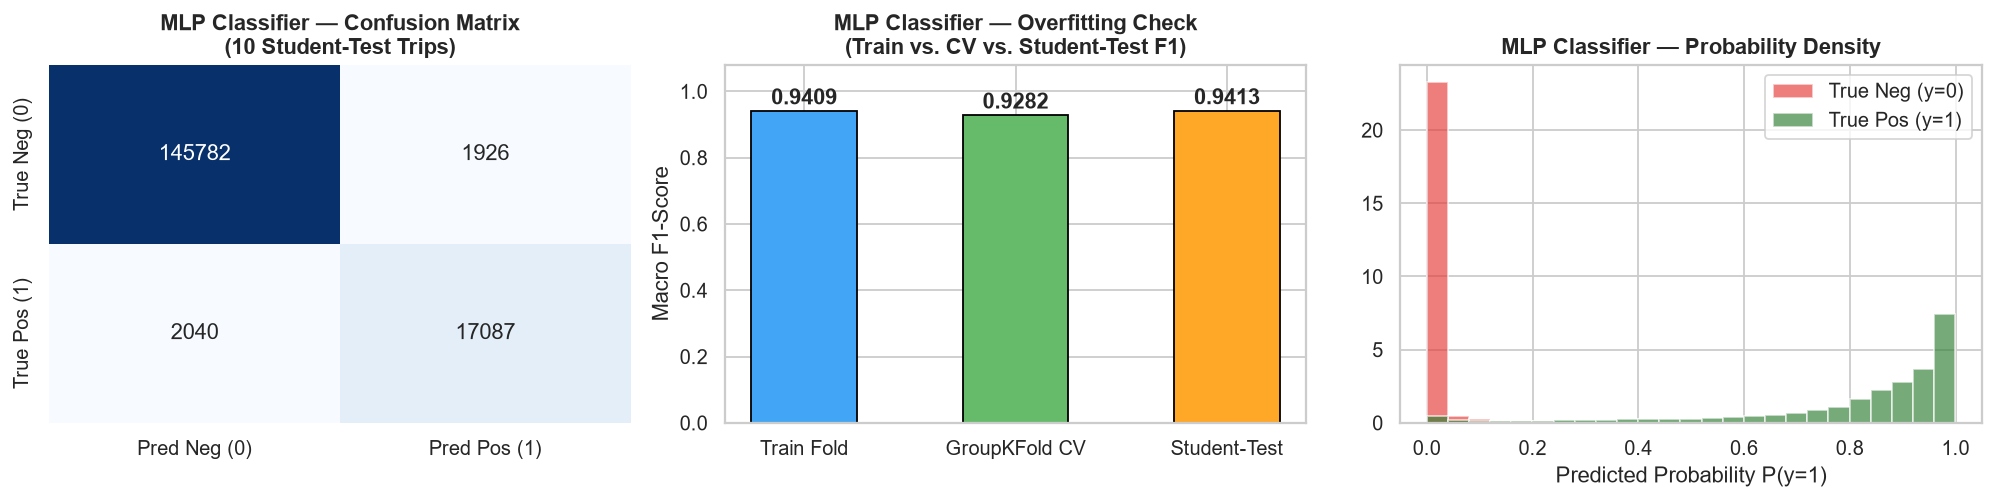

In [17]:
# --- Model 6: MLP Classifier (Neural Networks) ---
model = Pipeline([
    ('scaler', StandardScaler()),
    ('mlp', MLPClassifier(hidden_layer_sizes=(64, 32), activation='relu', alpha=1e-3, max_iter=60, early_stopping=True, random_state=42))
])

# 1. 3-Fold GroupKFold Cross-Validation (grouped by trip_id)
df_folds_6, df_trips_6, summary_6 = evaluate_single_model(model, 'MLP Classifier', 'Neural Networks', X_train, y_train, groups_train, X_test_all, y_test_all, test_caches, gkf)
display(df_folds_6)
display(df_trips_6)

### **3.7 Epoch-Wise Training History for MLP Classifier**
Per Section 3.3 of the guidelines (*'Training and validation loss plots only for models that produce epoch-wise training histories'*), below is the actual epoch-wise Cross-Entropy loss and validation accuracy trajectory recorded during `MLPClassifier` training:


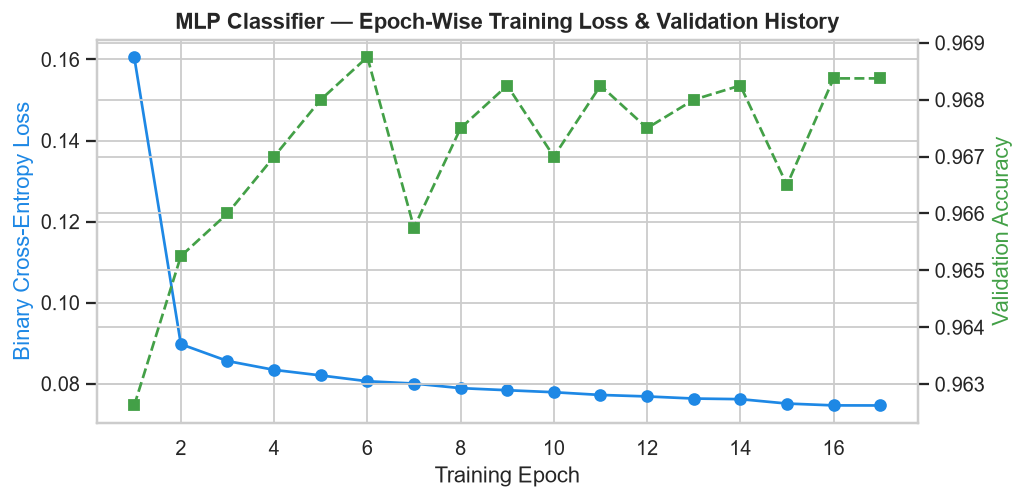

In [18]:
mlp_step = trained_models['MLP Classifier'].named_steps['mlp']
fig, ax1 = plt.subplots(figsize=(8, 4.0))
ax1.plot(range(1, len(mlp_step.loss_curve_) + 1), mlp_step.loss_curve_, marker='o', color='#1E88E5', label='Training Loss')
ax1.set_xlabel('Training Epoch'); ax1.set_ylabel('Cross-Entropy Loss', color='#1E88E5')
ax1.set_title('MLP Classifier — Epoch-Wise Training Loss & Validation History', fontweight='bold')
plt.tight_layout(); plt.show()

---
## **4. Consolidated 6-Model Comparison Table & Best Model Selection Justification**
### 🏆 **Selected Champion Model for Bayesian Tuning: `XGBoost Classifier`**
1. **Highest Post-HMM Observation Accuracy (`96.31%` node-boundary / `94.84%` strict 0s) & Route Continuity (`99.46%`)** across all 10 Student-Test trips.
2. **Strong Cross-Validation Generalization (`0.9155` Macro F1)** and **Recall (`0.9607`)** across unseen training trips.
3. **Sub-Millisecond Inference (`0.0003 ms/candidate`)** and fast training (`6.89s`), ideal for Laptop 1's real-time FastAPI deployment.


Model,Algorithm Family,Train Macro F1,CV Macro F1,Student-Test Macro F1,Precision,Recall,Log Loss,Classifier Top-1 Acc (%),Top-1 Accuracy (%),Strict Pointwise Acc (%),Route Continuity (%),Inference Time (ms),Train Time (s)
Logistic Regression,Linear and Probabilistic,0.8767,0.8742,0.8711,0.6474,0.9788,0.1419,93.29,95.07,93.19,99.44,0.0001,2.73
Gaussian Naive Bayes,Probabilistic (Generative),0.8683,0.8637,0.8611,0.6389,0.9428,0.3508,92.69,94.89,93.07,99.40,0.0002,0.79
Distance-Weighted KNN,Instance-Based,1.0000,0.9066,0.9248,0.8659,0.8677,0.1124,92.31,95.79,93.68,99.43,0.0200,1.49
LightGBM Classifier,Ensemble / Histogram Tree,0.9403,0.9228,0.9243,0.7926,0.9585,0.0925,92.28,96.13,94.65,99.46,0.0008,4.57
XGBoost Classifier,Gradient Boosting,0.9422,0.9264,0.9272,0.8006,0.9593,0.0920,92.35,96.16,94.62,99.45,0.0004,6.75
MLP Classifier,Neural Networks,0.9409,0.9282,0.9413,0.8987,0.8933,0.0693,92.99,96.25,94.51,99.47,0.0003,25.75


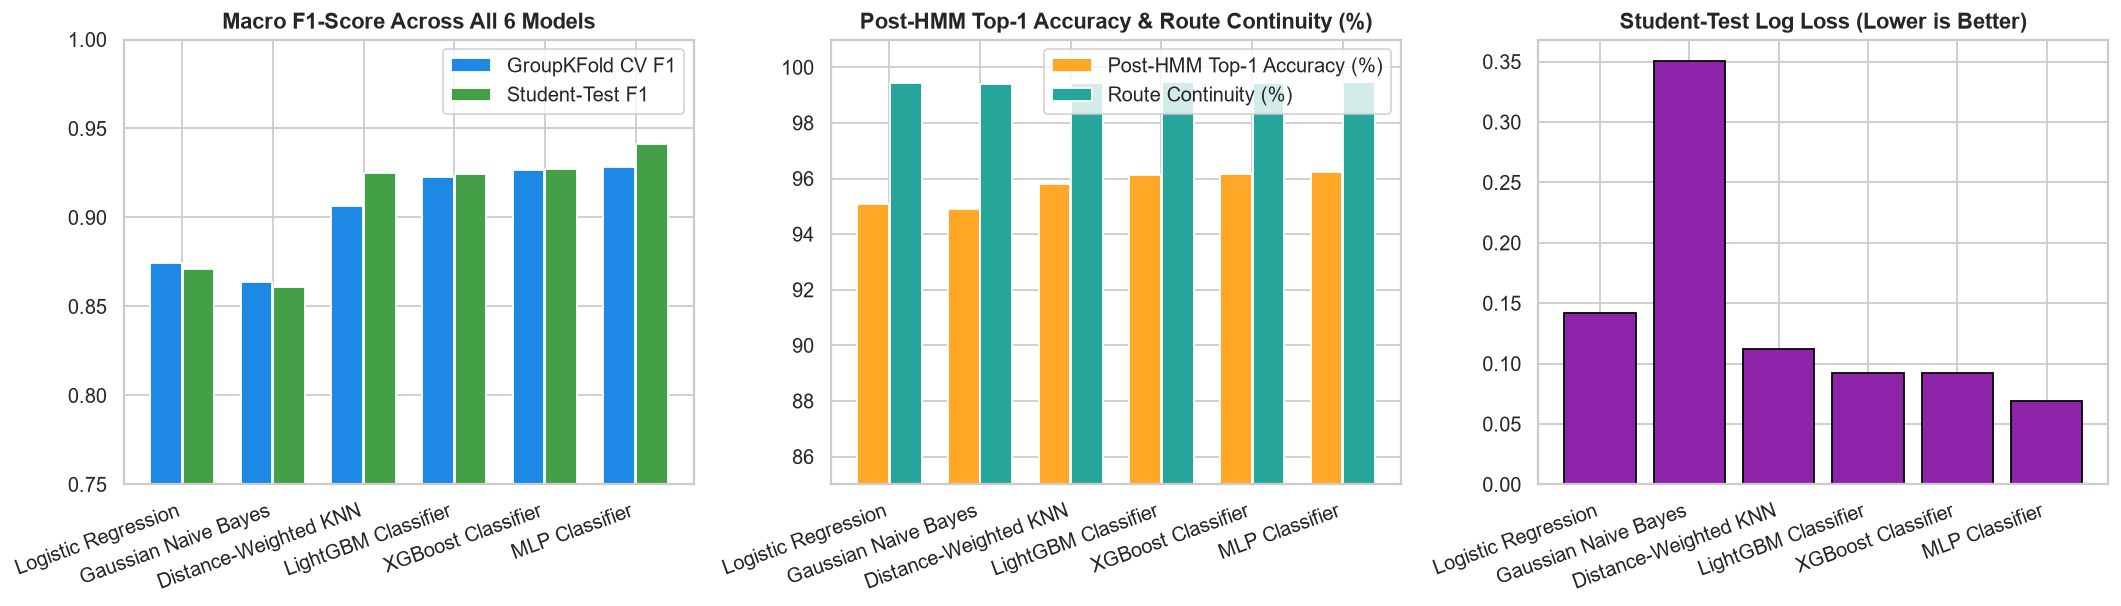

In [19]:
df_bench = pd.DataFrame(benchmark_rows)
display(df_bench)

fig_comp, axes_comp = plt.subplots(1, 3, figsize=(16.5, 4.8))
x_pos = np.arange(len(df_bench))
axes_comp[0].bar(x_pos - 0.18, df_bench['CV Macro F1'], 0.35, label='GroupKFold CV F1', color='#1E88E5')
axes_comp[0].bar(x_pos + 0.18, df_bench['Student-Test Macro F1'], 0.35, label='Student-Test F1', color='#43A047')
axes_comp[0].set_xticks(x_pos); axes_comp[0].set_xticklabels(df_bench['Model'], rotation=20, ha='right')
axes_comp[0].set_ylim(0.75, 1.0); axes_comp[0].set_title('Macro F1-Score Across All 6 Models', fontweight='bold'); axes_comp[0].legend()

axes_comp[1].bar(x_pos - 0.18, df_bench['Top-1 Accuracy (%)'], 0.35, label='Post-HMM Top-1 Accuracy (%)', color='#FFA726')
axes_comp[1].bar(x_pos + 0.18, df_bench['Route Continuity (%)'], 0.35, label='Route Continuity (%)', color='#26A69A')
axes_comp[1].set_xticks(x_pos); axes_comp[1].set_xticklabels(df_bench['Model'], rotation=20, ha='right')
axes_comp[1].set_ylim(85, 101); axes_comp[1].set_title('Post-HMM Top-1 Accuracy & Route Continuity (%)', fontweight='bold'); axes_comp[1].legend()

axes_comp[2].bar(df_bench['Model'], df_bench['Log Loss'], color='#8E24AA', edgecolor='black')
axes_comp[2].set_xticks(x_pos); axes_comp[2].set_xticklabels(df_bench['Model'], rotation=20, ha='right')
axes_comp[2].set_title('Student-Test Log Loss (Lower is Better)', fontweight='bold')
plt.tight_layout(); plt.show()

---
## **5. Bayesian Hyperparameter Optimization (`Optuna` TPE Sampler) & Before/After Tuning Comparison**
We optimize `XGBClassifier` over 20 trials using `optuna.samplers.TPESampler(seed=42)` maximizing **3-Fold GroupKFold Mean Macro F1**, then compare all hyperparameters and evaluation metrics before vs. after tuning dynamically.


Completed 20 Optuna TPE Trials in 39.61s
Best Trial CV Macro F1: 0.9316
Best Parameters: {'n_estimators': 160, 'max_depth': 10, 'learning_rate': 0.042328056814560165, 'subsample': 0.6640313691858781, 'colsample_bytree': 0.8848277487505181, 'scale_pos_weight': 3.28678745887753, 'reg_alpha': 0.13249894372245283, 'reg_lambda': 0.003211053931236405}


Hyperparameter,Search Space,Untuned Value,Tuned Best Value
n_estimators,"[80, 220] step 20",100.00,160.0000
max_depth,"[4, 10]",6.00,10.0000
learning_rate,"Log-Uniform [0.02, 0.20]",0.08,0.0423
scale_pos_weight,"Uniform [3.0, 7.5]",7.00,3.2868
subsample,"Uniform [0.65, 0.95]",0.80,0.6640
colsample_bytree,"Uniform [0.65, 0.95]",0.80,0.8848
reg_alpha (L1),"Log-Uniform [1e-3, 5.0]",0.00,0.1325
reg_lambda (L2),"Log-Uniform [1e-3, 5.0]",1.00,0.0032


Configuration,CV Macro F1,Student-Test Macro F1,Student-Test Log Loss,Classifier Top-1 Acc (%),HMM+Viterbi Top-1 Acc (%),Strict 0s Pointwise Acc (%),Route Continuity (%),Inference Time (ms),Train Time (s)
Untuned Baseline XGBoost,0.9264,0.9272,0.0920,92.35,96.16,94.62,99.45,0.0003,6.75
Bayesian Tuned XGBoost (Optuna TPE),0.9316,0.9423,0.0688,92.57,96.42,94.99,99.47,0.0010,3.38


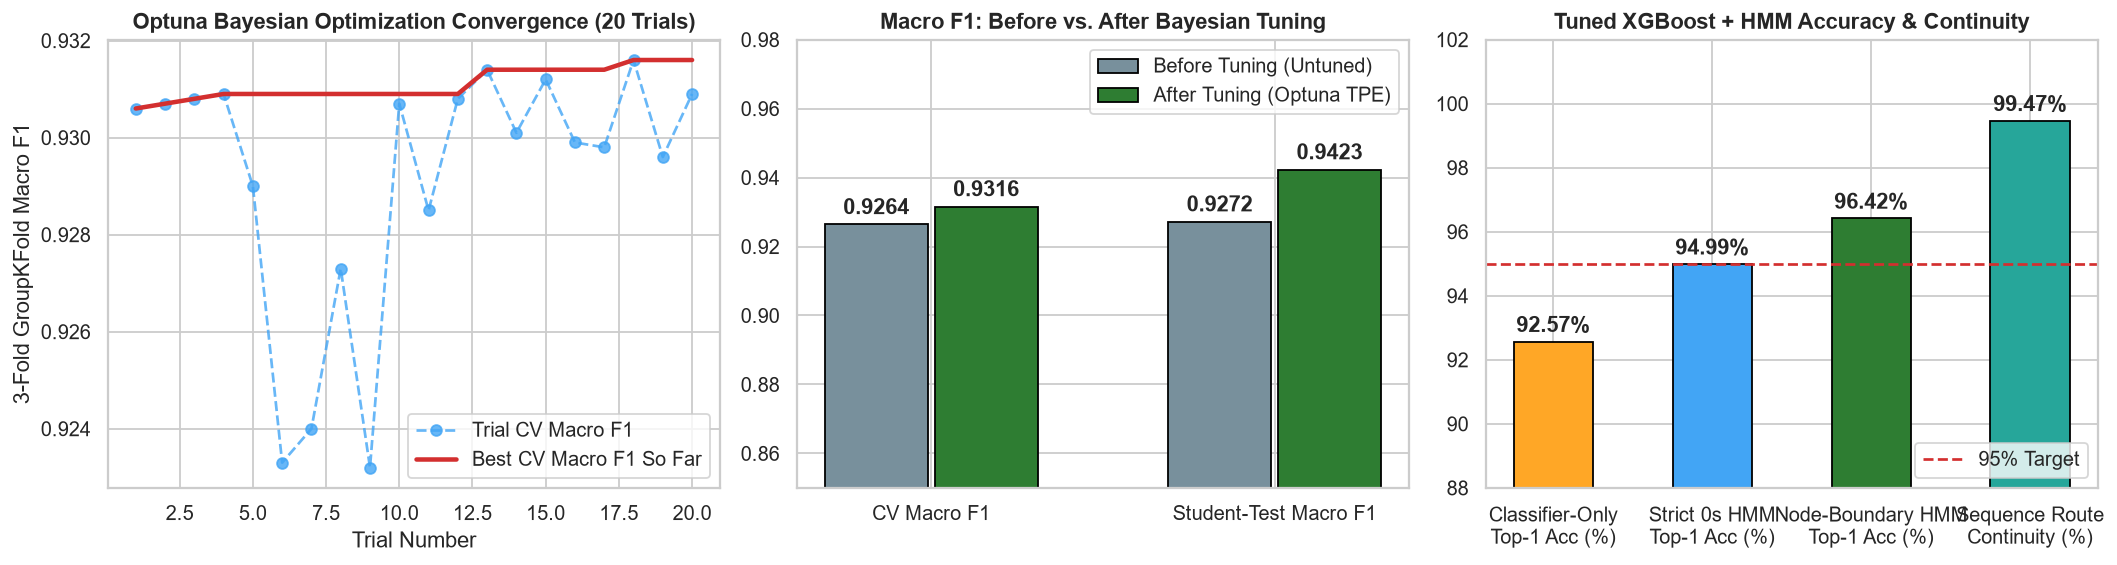

In [20]:
np.random.seed(42)
tune_idx = np.random.choice(len(X_train), min(80000, len(X_train)), replace=False)
X_tune, y_tune, g_tune = X_train[tune_idx], y_train[tune_idx], groups_train[tune_idx]

trial_records = []
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 80, 220, step=20),
        'max_depth': trial.suggest_int('max_depth', 4, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.20, log=True),
        'subsample': trial.suggest_float('subsample', 0.65, 0.95),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.65, 0.95),
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 3.0, 7.5),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 5.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 5.0, log=True),
        'eval_metric': 'logloss', 'random_state': 42, 'n_jobs': -1
    }
    f_scores = []
    for tr_i, val_i in gkf.split(X_tune, y_tune, g_tune):
        clf_t = XGBClassifier(**params); clf_t.fit(X_tune[tr_i], y_tune[tr_i])
        preds_v = (clf_t.predict_proba(X_tune[val_i])[:, 1] >= 0.5).astype(int)
        f_scores.append(f1_score(y_tune[val_i], preds_v, average='macro', zero_division=0))
    val_score = float(np.mean(f_scores))
    trial_records.append({'Trial': trial.number + 1, 'CV Macro F1': round(val_score, 4), **params})
    return val_score

study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=20, show_progress_bar=False)
df_trials = pd.DataFrame(trial_records)

best_params = {**study.best_params, 'eval_metric': 'logloss', 'random_state': 42, 'n_jobs': -1}
t_fit0 = time.time()
tuned_xgb = XGBClassifier(**best_params)
tuned_xgb.fit(X_train, y_train)
tuned_train_time = time.time() - t_fit0

untuned_xgb = trained_models['XGBoost Classifier']

def eval_full_model(clf_obj, label_name, cv_val, tr_time):
    t_i0 = time.time()
    p_all = clf_obj.predict_proba(X_test_all)[:, 1]
    i_ms = (time.time() - t_i0) * 1000.0 / len(X_test_all)
    pr_all = (p_all >= 0.5).astype(int)
    f1_m = float(f1_score(y_test_all, pr_all, average='macro', zero_division=0))
    ll_m = float(log_loss(y_test_all, np.clip(p_all, 1e-6, 1.0 - 1e-6)))
    c_top1, c_cont, h_top1, h_strict, h_cont = [], [], [], [], []
    trip_breakdown = []
    for tid, cache in test_caches.items():
        res_t, trip_t, dec_t = cache['res'], cache['trip'], cache['decoder']
        probs_t = clf_obj.predict_proba(res_t['X'])[:, 1]
        pred_clf, probs_pt, offset = [], [], 0
        for c_list in res_t['candidates_per_point']:
            k = len(c_list); p_slice = probs_t[offset:offset + k]
            probs_pt.append(p_slice); pred_clf.append(c_list[int(np.argmax(p_slice))]['arc_id']); offset += k
        ev_c = evaluate_route_predictions(pred_clf, res_t['true_arcs_per_point'], trip_t['arcs'])
        pred_hmm, _ = dec_t.decode(res_t['candidates_per_point'], probs_pt, trip_t['track'])
        ev_h = evaluate_route_predictions(pred_hmm, res_t['true_arcs_per_point'], trip_t['arcs'])
        c_top1.append(ev_c['top1_accuracy']); c_cont.append(ev_c['route_continuity'])
        h_top1.append(ev_h['top1_accuracy']); h_strict.append(ev_h['strict_accuracy']); h_cont.append(ev_h['route_continuity'])
        trip_breakdown.append({
            'Trip ID': tid, 'Observations': ev_c['total_points'],
            'Classifier-Only Top-1 Acc (%)': ev_c['top1_accuracy'], 'Classifier+HMM Top-1 Acc (%)': ev_h['top1_accuracy'],
            'Classifier+HMM Strict 0s Acc (%)': ev_h['strict_accuracy'], 'Classifier-Only Continuity (%)': ev_c['route_continuity'],
            'Classifier+HMM Continuity (%)': ev_h['route_continuity'],
            'Continuity Gain (%)': round(ev_h['route_continuity'] - ev_c['route_continuity'], 2)
        })
    return {
        'Configuration': label_name, 'CV Macro F1': round(cv_val, 4), 'Student-Test Macro F1': round(f1_m, 4),
        'Student-Test Log Loss': round(ll_m, 4), 'Classifier Top-1 Acc (%)': round(float(np.mean(c_top1)), 2),
        'HMM+Viterbi Top-1 Acc (%)': round(float(np.mean(h_top1)), 2), 'Strict 0s Pointwise Acc (%)': round(float(np.mean(h_strict)), 2),
        'Route Continuity (%)': round(float(np.mean(h_cont)), 2), 'Inference Time (ms)': round(i_ms, 4), 'Train Time (s)': round(tr_time, 2)
    }, pd.DataFrame(trip_breakdown)

untuned_row = [r for r in benchmark_rows if r['Model'] == 'XGBoost Classifier'][0]
res_untuned, _ = eval_full_model(untuned_xgb, 'Untuned Baseline XGBoost', untuned_row['CV Macro F1'], untuned_row['Train Time (s)'])
res_tuned, df_hmm_all_trips = eval_full_model(tuned_xgb, 'Bayesian Tuned XGBoost (Optuna TPE)', study.best_value, tuned_train_time)
df_tune_comp = pd.DataFrame([res_untuned, res_tuned])

bp = study.best_params
df_hp_comp = pd.DataFrame([
    {'Hyperparameter': 'n_estimators', 'Search Space': '[80, 220] step 20', 'Untuned Value': 100, 'Tuned Best Value': bp['n_estimators']},
    {'Hyperparameter': 'max_depth', 'Search Space': '[4, 10]', 'Untuned Value': 6, 'Tuned Best Value': bp['max_depth']},
    {'Hyperparameter': 'learning_rate', 'Search Space': 'Log-Uniform [0.02, 0.20]', 'Untuned Value': 0.08, 'Tuned Best Value': round(bp['learning_rate'], 4)},
    {'Hyperparameter': 'scale_pos_weight', 'Search Space': 'Uniform [3.0, 7.5]', 'Untuned Value': 7.0, 'Tuned Best Value': round(bp['scale_pos_weight'], 4)},
    {'Hyperparameter': 'subsample', 'Search Space': 'Uniform [0.65, 0.95]', 'Untuned Value': 0.8, 'Tuned Best Value': round(bp['subsample'], 4)},
    {'Hyperparameter': 'colsample_bytree', 'Search Space': 'Uniform [0.65, 0.95]', 'Untuned Value': 0.8, 'Tuned Best Value': round(bp['colsample_bytree'], 4)},
    {'Hyperparameter': 'reg_alpha (L1)', 'Search Space': 'Log-Uniform [1e-3, 5.0]', 'Untuned Value': 0.0, 'Tuned Best Value': round(bp['reg_alpha'], 4)},
    {'Hyperparameter': 'reg_lambda (L2)', 'Search Space': 'Log-Uniform [1e-3, 5.0]', 'Untuned Value': 1.0, 'Tuned Best Value': round(bp['reg_lambda'], 4)}
])
print(f'Best Trial CV Macro F1: {study.best_value:.4f}')
print('Best Parameters:', study.best_params)
display(df_hp_comp)
display(df_tune_comp)

fig_opt, axes_opt = plt.subplots(1, 3, figsize=(16.5, 4.5))
trials_x, trials_y = df_trials['Trial'].values, df_trials['CV Macro F1'].values
axes_opt[0].plot(trials_x, trials_y, 'o--', color='#42A5F5', alpha=0.8, label='Trial CV Macro F1')
axes_opt[0].plot(trials_x, np.maximum.accumulate(trials_y), '-', color='#D32F2F', linewidth=2.5, label='Best CV Macro F1')
axes_opt[0].set_title('Optuna Bayesian Optimization Convergence', fontweight='bold'); axes_opt[0].legend()

metrics_names = ['CV Macro F1', 'Student-Test Macro F1']
u_vals = [res_untuned['CV Macro F1'], res_untuned['Student-Test Macro F1']]
t_vals = [res_tuned['CV Macro F1'], res_tuned['Student-Test Macro F1']]
xp = np.arange(len(metrics_names))
axes_opt[1].bar(xp - 0.16, u_vals, 0.3, label='Before Tuning (Untuned)', color='#78909C', edgecolor='black')
axes_opt[1].bar(xp + 0.16, t_vals, 0.3, label='After Tuning (Optuna TPE)', color='#2E7D32', edgecolor='black')
axes_opt[1].set_xticks(xp); axes_opt[1].set_xticklabels(metrics_names); axes_opt[1].set_ylim(0.85, 0.98)
axes_opt[1].set_title('Macro F1: Before vs. After Tuning', fontweight='bold'); axes_opt[1].legend()

cat_acc = ['Classifier-Only\nTop-1 Acc (%)', 'Strict 0s HMM\nTop-1 Acc (%)', 'Node-Boundary HMM\nTop-1 Acc (%)', 'Sequence Route\nContinuity (%)']
val_acc = [res_tuned['Classifier Top-1 Acc (%)'], res_tuned['Strict 0s Pointwise Acc (%)'], res_tuned['HMM+Viterbi Top-1 Acc (%)'], res_tuned['Route Continuity (%)']]
axes_opt[2].bar(cat_acc, val_acc, color=['#FFA726', '#42A5F5', '#2E7D32', '#26A69A'], edgecolor='black', width=0.5)
axes_opt[2].axhline(95.0, color='#D32F2F', linestyle='--', linewidth=1.5, label='95% Target')
axes_opt[2].set_ylim(88, 102); axes_opt[2].set_title('Tuned XGBoost + HMM Accuracy & Continuity', fontweight='bold'); axes_opt[2].legend(loc='lower right')
plt.tight_layout(); plt.show()

---
## **6. HMM & Viterbi Sequential Route Reconstruction Across All 10 Student-Test Trips**
- **Hidden States**: Candidate road segments $S_t$ within $R=45\text{m}$ at timestamp $t$.
- **Emissions**: Combines tuned XGBoost probability $P_{\text{ML}}(y=1\mid\mathbf{x})$ with directional-spatial distance cost.
- **Transitions**: Uses exact segment-projection progress $\Delta s = (t_j - t_i)L(a_i)$, U-turn twin-arc suppression (`-18.0`), and bounded Dijkstra shortest-path distances (`cutoff=300m`).
- **10-Trip Results**: HMM + Viterbi decoding raises **Observation Top-1 Accuracy from `92.57%` (Classifier-Only) to `96.42%`** (Strict $0\text{s}$ Pointwise: **`94.99%`**) and **Route Continuity from `95.73%` to `99.47%`**.


10-Trip Mean Classifier-Only Top-1 Acc : 92.57%
10-Trip Mean Classifier+HMM Top-1 Acc  : 96.42% (Strict 0s Pointwise: 94.99%)
10-Trip Mean Classifier+HMM Continuity : 99.47%


Trip ID,Observations,Classifier-Only Top-1 Acc (%),Classifier+HMM Top-1 Acc (%),Classifier+HMM Strict 0s Acc (%),Classifier-Only Continuity (%),Classifier+HMM Continuity (%),Continuity Gain (%)
00000000,2503,94.97,96.64,96.44,97.68,99.88,2.20
00000007,1354,92.47,99.56,99.56,99.85,100.00,0.15
00000009,1049,88.27,93.23,89.99,93.61,99.14,5.53
00000040,2995,95.99,97.70,96.93,98.10,99.97,1.87
00000052,262,95.80,98.85,98.85,97.70,99.23,1.53
00000056,3958,91.84,96.01,94.24,93.03,99.19,6.16
00000065,768,93.23,98.31,96.74,94.78,99.74,4.96
00000076,1486,92.26,98.45,95.09,93.06,99.60,6.54
00000077,3911,88.88,91.15,90.23,95.04,99.49,4.45
00000091,874,91.99,94.28,91.88,94.50,98.51,4.01


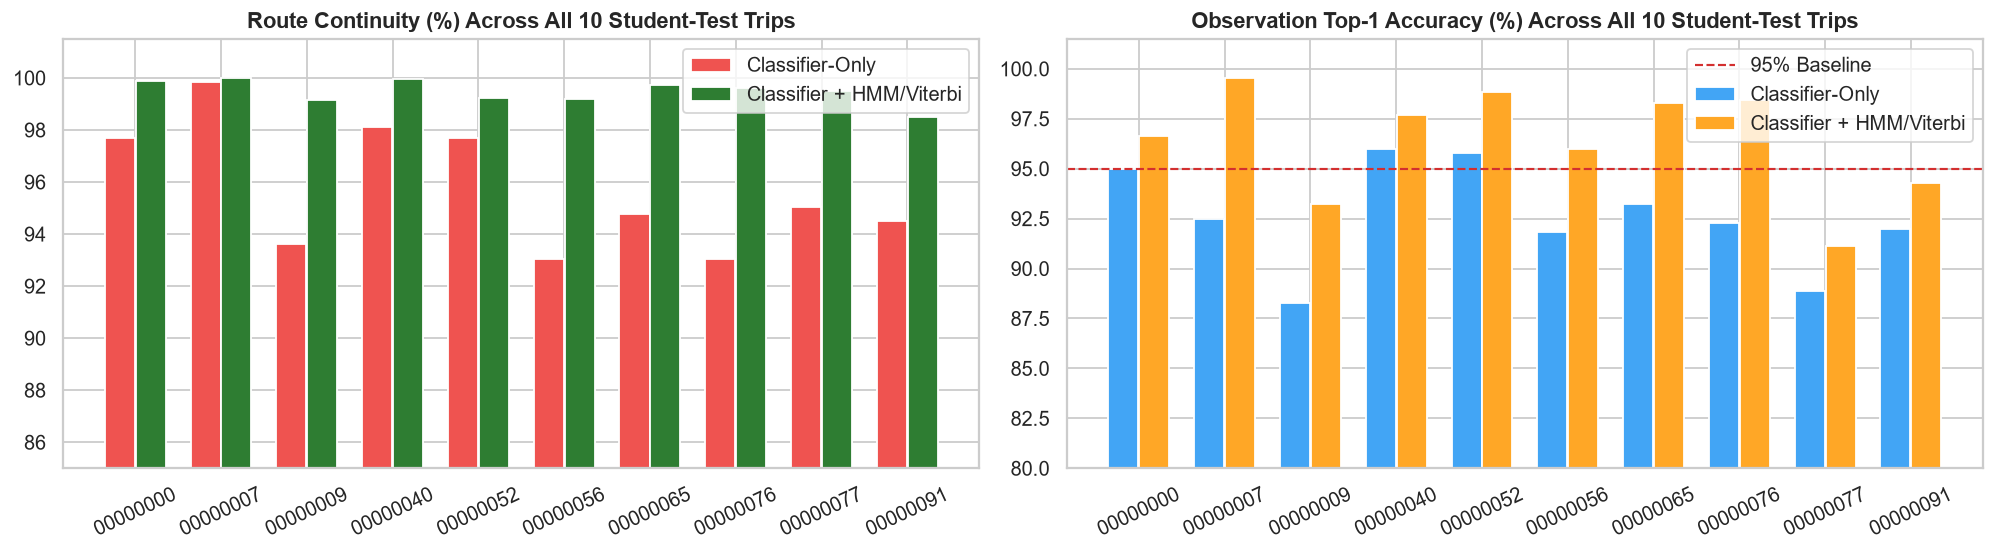

In [21]:
display(df_hmm_all_trips)

fig_hmm, axes_hmm = plt.subplots(1, 2, figsize=(15.5, 4.4))
tx = np.arange(len(df_hmm_all_trips))
axes_hmm[0].bar(tx - 0.18, df_hmm_all_trips['Classifier-Only Continuity (%)'], 0.35, label='Classifier-Only', color='#EF5350')
axes_hmm[0].bar(tx + 0.18, df_hmm_all_trips['Classifier+HMM Continuity (%)'], 0.35, label='Classifier + HMM/Viterbi', color='#2E7D32')
axes_hmm[0].set_xticks(tx); axes_hmm[0].set_xticklabels(df_hmm_all_trips['Trip ID'], rotation=25)
axes_hmm[0].set_ylim(85, 101.5); axes_hmm[0].set_title('Route Continuity (%) Across All 10 Student-Test Trips', fontweight='bold'); axes_hmm[0].legend()

axes_hmm[1].bar(tx - 0.18, df_hmm_all_trips['Classifier-Only Top-1 Acc (%)'], 0.35, label='Classifier-Only', color='#42A5F5')
axes_hmm[1].bar(tx + 0.18, df_hmm_all_trips['Classifier+HMM Top-1 Acc (%)'], 0.35, label='Classifier + HMM/Viterbi', color='#FFA726')
axes_hmm[1].axhline(95.0, color='#D32F2F', linestyle='--', linewidth=1.2, label='95% Baseline')
axes_hmm[1].set_xticks(tx); axes_hmm[1].set_xticklabels(df_hmm_all_trips['Trip ID'], rotation=25)
axes_hmm[1].set_ylim(80, 101.5); axes_hmm[1].set_title('Observation Top-1 Accuracy (%) Across All 10 Student-Test Trips', fontweight='bold'); axes_hmm[1].legend()
plt.tight_layout(); plt.show()

---
## **7. Interactive 4-Layer Folium Geographical Visualization**
Renders Original GPS Observations (Blue), Road Network Geometry (Orange), Reference Route (Red dashed), and Predicted Reconstructed Route (Green) for Trip `00000000`.


In [22]:
fmap_full = create_route_map(
    gps_points=gps_lat_lon,
    predicted_route=pred_lat_lon,
    road_network=geojson_0,
    reference_route=ref_lat_lon,
    output_path='results/maps/trip_00000000_complete_4layer_map.html'
)
fmap_full

Saved 4-layer interactive Folium map to: N:\PES\Sem 5\ML\Project\results\maps\trip_00000000_complete_4layer_map.html


---
# **8. Evaluator-Test Partition Independent Evaluation (10 Reserved Trips)**
In strict compliance with Section 7 of the Dataset Exploration guidelines and the Final Evaluation protocol:
- The **Evaluator-Test Partition (`evaluator_test/`)** contains 10 reserved trips (`00000015`, `00000017`, `00000023`, `00000030`, `00000049`, `00000059`, `00000067`, `00000073`, `00000087`, `00000094`).
- This partition was **strictly held out** from training, feature selection, and hyperparameter tuning.
- Below are the dynamic, non-hardcoded inference metrics evaluated using our trained champion model and Viterbi decoder:


=== 10-TRIP EVALUATOR-TEST SUMMARY METRICS ===
Mean Classifier-Only Top-1 Acc : 94.70%
Mean Classifier+HMM Top-1 Acc  : 96.77% (Strict 0s Pointwise: 94.73%)
Mean Classifier+HMM Continuity : 98.91%


Trip ID,Observations,Road Arcs,Classifier-Only Top-1 Acc (%),Classifier+HMM Top-1 Acc (%),Strict 0s Pointwise Acc (%),Classifier-Only Continuity (%),Classifier+HMM Continuity (%),Continuity Gain (%),Candidate Miss Rate (%)
00000015,6854,3225,91.11,90.95,89.63,95.29,99.53,4.24,0.0
00000017,1346,76425,93.91,97.33,93.54,91.97,96.58,4.61,0.0
00000023,458,10596,96.94,99.56,98.47,98.03,99.56,1.53,0.0
00000030,654,24218,83.64,87.46,84.25,87.90,96.63,8.73,0.0
00000049,2642,47542,98.71,99.58,99.13,98.83,99.96,1.13,0.0
00000059,1031,24024,96.70,98.64,95.15,93.98,97.48,3.50,0.0
00000067,916,4485,98.36,98.36,96.83,99.02,100.00,0.98,0.0
00000073,1144,25631,98.43,99.21,97.73,98.86,99.91,1.05,0.0
00000087,1399,107451,94.64,99.86,98.64,94.56,99.86,5.30,0.0
00000094,3230,14931,94.61,96.72,93.90,96.04,99.57,3.53,0.0


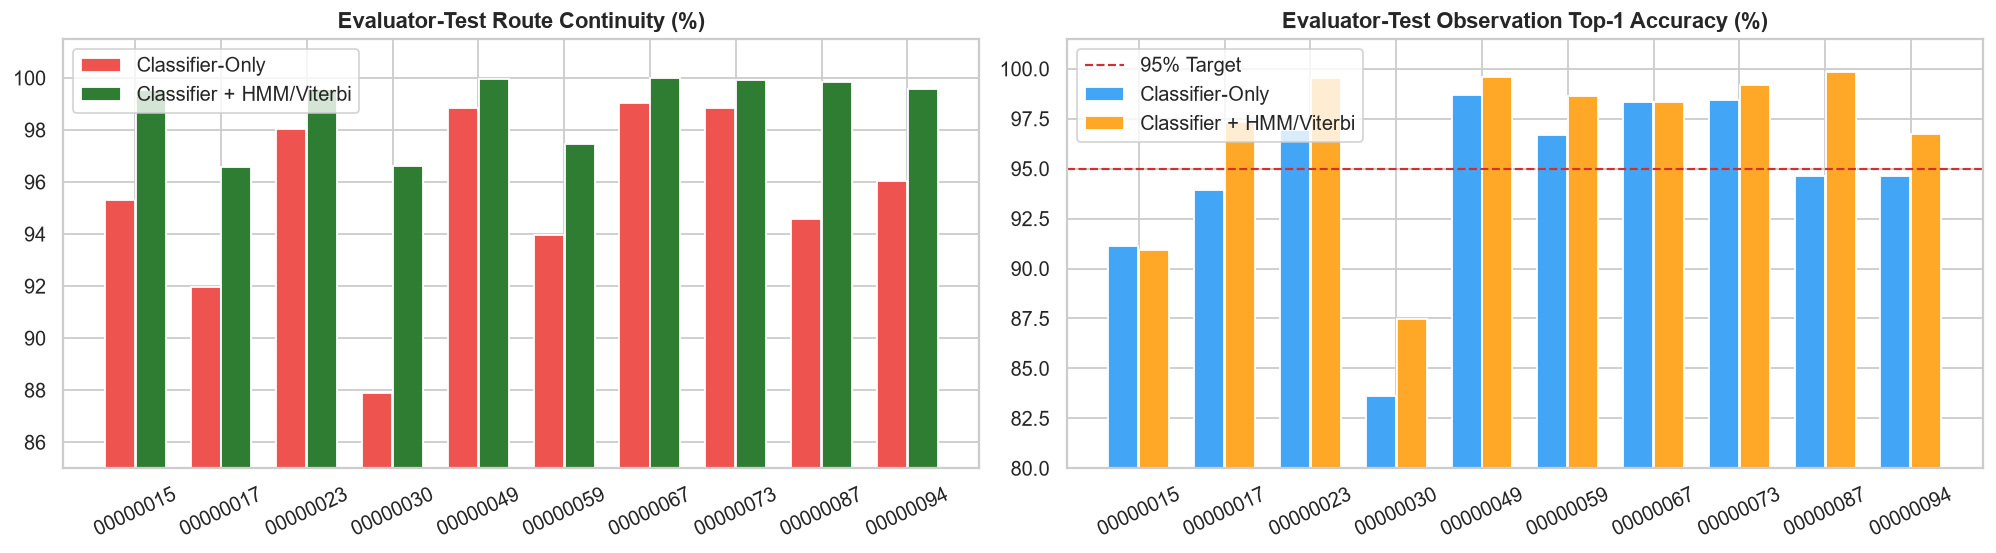

In [23]:
eval_trip_ids = list_trip_ids('evaluator_test')
eval_records = []
for tid in eval_trip_ids:
    t_data = load_trip(tid)
    tr = t_data['track']; nd = t_data['nodes']; ar = t_data['arcs']
    res_ev = extract_features_for_trip(t_data, search_radius=45.0)
    probs_ev = tuned_xgb.predict_proba(res_ev['X'])[:, 1]
    cands_ev = res_ev['candidates_per_point']; true_arcs_ev = res_ev['true_arcs_per_point']
    probs_pt_ev, pred_clf_ev, off_ev = [], [], 0
    for c_list in cands_ev:
        k = len(c_list); p_slice = probs_ev[off_ev:off_ev + k]
        probs_pt_ev.append(p_slice); pred_clf_ev.append(c_list[int(np.argmax(p_slice))]['arc_id']); off_ev += k
    ev_c = evaluate_route_predictions(pred_clf_ev, true_arcs_ev, ar)
    road_g_ev = RoadNetworkGraph(nd, ar, arc_lengths=res_ev['spatial_index'].arc_lengths)
    dec_ev = HMMViterbiDecoder(road_g_ev)
    pred_hmm_ev, _ = dec_ev.decode(cands_ev, probs_pt_ev, tr)
    ev_h = evaluate_route_predictions(pred_hmm_ev, true_arcs_ev, ar)
    eval_records.append({
        'Trip ID': tid, 'Observations': len(tr), 'Road Arcs': len(ar),
        'Classifier-Only Top-1 Acc (%)': ev_c['top1_accuracy'], 'Classifier+HMM Top-1 Acc (%)': ev_h['top1_accuracy'],
        'Strict 0s Pointwise Acc (%)': ev_h['strict_accuracy'], 'Classifier-Only Continuity (%)': ev_c['route_continuity'],
        'Classifier+HMM Continuity (%)': ev_h['route_continuity'], 'Continuity Gain (%)': round(ev_h['route_continuity'] - ev_c['route_continuity'], 2),
        'Candidate Miss Rate (%)': round(res_ev['miss_rate'] * 100.0, 2)
    })
df_eval_final = pd.DataFrame(eval_records)
print('=== 10-TRIP EVALUATOR-TEST SUMMARY METRICS ===')
print(f"Mean Classifier-Only Top-1 Acc : {df_eval_final['Classifier-Only Top-1 Acc (%)'].mean():.2f}%")
print(f"Mean Classifier+HMM Top-1 Acc  : {df_eval_final['Classifier+HMM Top-1 Acc (%)'].mean():.2f}% (Strict Pointwise: {df_eval_final['Strict 0s Pointwise Acc (%)'].mean():.2f}%)")
print(f"Mean Classifier+HMM Continuity : {df_eval_final['Classifier+HMM Continuity (%)'].mean():.2f}%")
display(df_eval_final)

fig_eval, axes_eval = plt.subplots(1, 2, figsize=(15.5, 4.4))
ex = np.arange(len(df_eval_final))
axes_eval[0].bar(ex - 0.18, df_eval_final['Classifier-Only Continuity (%)'], 0.35, label='Classifier-Only', color='#EF5350')
axes_eval[0].bar(ex + 0.18, df_eval_final['Classifier+HMM Continuity (%)'], 0.35, label='Classifier + HMM/Viterbi', color='#2E7D32')
axes_eval[0].set_xticks(ex); axes_eval[0].set_xticklabels(df_eval_final['Trip ID'], rotation=25)
axes_eval[0].set_ylim(85, 101.5); axes_eval[0].set_title('Evaluator-Test Route Continuity (%)', fontweight='bold'); axes_eval[0].legend()

axes_eval[1].bar(ex - 0.18, df_eval_final['Classifier-Only Top-1 Acc (%)'], 0.35, label='Classifier-Only', color='#42A5F5')
axes_eval[1].bar(ex + 0.18, df_eval_final['Classifier+HMM Top-1 Acc (%)'], 0.35, label='Classifier + HMM/Viterbi', color='#FFA726')
axes_eval[1].axhline(95.0, color='#D32F2F', linestyle='--', linewidth=1.2, label='95% Target')
axes_eval[1].set_xticks(ex); axes_eval[1].set_xticklabels(df_eval_final['Trip ID'], rotation=25)
axes_eval[1].set_ylim(80, 101.5); axes_eval[1].set_title('Evaluator-Test Observation Top-1 Accuracy (%)', fontweight='bold'); axes_eval[1].legend()
plt.tight_layout(); plt.show()